In [2]:
!pip install joblib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pickle
import os
import csv
import gc
import itertools
from tqdm import tqdm
import multiprocessing
from multiprocessing import Pool, cpu_count
from collections import defaultdict
import snappy
from sage.all import matrix, ZZ, identity_matrix, RealField
from tqdm.auto import tqdm
from joblib import Parallel, delayed
CSV_FILE = 'modular_knots_results7.csv'
MAX_LENGTH = 23
CHUNK_SIZE = int(10000)
CHUNK = int(100)
cores= 15

In [2]:
CHECKPOINT_FILE = 'modular_words_state_parallel.pkl'
def get_cyclic_permutations(word):
    return [word[i:] + word[:i] for i in range(len(word))]
def is_primitive(word):
    """Returns True if word is not a repetition."""
    n = len(word)
    for d in range(1, n // 2 + 1):
        if n % d == 0:
            sub = word[:d]
            if sub * (n // d) == word: return False
    return True
def get_canonical(word):
    """Returns the alphabetically first rotation."""
    n = len(word)
    s = word + word
    return min(s[i:i+n] for i in range(n))
def word_to_weights(word):
    n = len(word)
    shifts = get_cyclic_permutations(word)
    indexed_shifts = [{'str': s, 'orig_idx': idx} for idx, s in enumerate(shifts)]
    sorted_shifts = sorted(indexed_shifts, key=lambda x: x['str'])
    weights = [0] * n
    for rank, item in enumerate(sorted_shifts):
        weights[item['orig_idx']] = rank
    return weights
class KnotDiagramFinal:
    def __init__(self, weights):
        self.weights = weights
        self.n = len(weights)
        self.strands = [{'start': weights[i], 'end': weights[(i+1)%self.n]} for i in range(self.n)]
        self.crossings_map = defaultdict(list)
        self.node_labels = {'top': defaultdict(list), 'bottom': defaultdict(list)}
        self.crossing_labels = {}
        self.trefoil_labels = []
        self.counter = 1
        self.mx = max(self.weights)
        for w in weights:
            self.node_labels['top'][w]
            self.node_labels['bottom'][w]
    def find_partition_weight(self):
        """
        Implements the logic: Find the weight at the index immediately preceding the maximum weight.
        This resolves the XXXYY=2 hardcoding issue.
        """
        max_weight = self.mx
        max_idx = self.weights.index(max_weight)
        idx_before_max = (max_idx - 1 + self.n) % self.n
        return self.weights[idx_before_max]
    def calculate_intersections(self):
        cid = 1
        for i in range(self.n):
            for j in range(i + 1, self.n):
                s1, s2 = self.strands[i], self.strands[j]
                d1, d2 = s1['end'] - s1['start'], s2['end'] - s2['start']
                if d1 == d2: continue
                try: t = (s2['start'] - s1['start']) / (d1 - d2)
                except: continue
                if 0 < t < 1:
                    c = {'id': f"C{cid}", 't': t}
                    self.crossings_map[i].append(c)
                    self.crossings_map[j].append(c)
                    cid += 1
        for i in range(self.n): self.crossings_map[i].sort(key=lambda x: x['t'])
    def run_passes(self):
        curr = self.weights.index(0)
        self.node_labels['top'][self.weights[curr]].append(1)
        self.node_labels['bottom'][self.weights[curr]].append(-2)
        self.counter = 3
        for i in range(self.n):
            s = self.strands[curr]
            sign = 1 if s['end'] > s['start'] else -1
            for c in self.crossings_map[curr]:
                if c['id'] not in self.crossing_labels: self.crossing_labels[c['id']] = []
                self.crossing_labels[c['id']].append(self.counter * sign)
                self.counter += 1
            ew = s['end']
            if ew == 0: break
            self.node_labels['top'][ew].append(self.counter); self.counter += 1
            self.node_labels['bottom'][ew].append(-1 * self.counter); self.counter += 1
            curr = self.weights.index(ew)
        MV = self.find_partition_weight()
        for w in range(0, MV + 1):
            if len(self.node_labels['bottom'][w]) < 2:
                self.node_labels['bottom'][w].append(self.counter); 
                self.counter+=1
        t_labels1 = list(range(self.counter, self.counter+3))
        self.counter += 3
        self.trefoil_labels.extend([t_labels1[0], -(t_labels1[1]), t_labels1[2]])
        for w in range(MV + 1, self.mx + 1):
            if len(self.node_labels['top'][w]) < 2: 
                self.node_labels['top'][w].append(-self.counter); 
                self.counter+=1
        for w in range(self.mx, MV, -1):
            if len(self.node_labels['bottom'][w]) < 2: 
                self.node_labels['bottom'][w].append(self.counter); 
                self.counter+=1
        t_labels2 = list(range(self.counter, self.counter+3))
        self.counter += 3
        self.trefoil_labels.extend([-(t_labels2[0]), (t_labels2[1]), -(t_labels2[2])])
        for w in range(MV, -1, -1):
            if len(self.node_labels['top'][w]) < 2: 
                self.node_labels['top'][w].append(-self.counter); 
                self.counter+=1
    def get_dt(self):
        pairs = []
        for w in self.weights: pairs.extend([self.node_labels['top'][w], self.node_labels['bottom'][w]])
        pairs.extend(self.crossing_labels.values())
        t1, t2 = self.trefoil_labels[:3], self.trefoil_labels[3:]
        trefoil_pairs = []
        for i in range(3):
            trefoil_pairs.append([t1[i], t2[i]])
        pairs.extend(trefoil_pairs)
        vp = [p for p in pairs if len(p)==2]
        if not vp: return "([],[])"
        mx = max(max(abs(x) for x in p) for p in vp)
        dt_size = (mx // 2) + 2
        dt = [0] * dt_size
        for v1, v2 in vp:
            o, e = (v1, v2) if abs(v1)%2!=0 else (v2, v1)
            idx = (abs(o)-1)//2
            if idx < dt_size: dt[idx] = e
        while dt and dt[-1] == 0: dt.pop()
        try:
            split_index = dt.index(-2)
            part1 = dt[:split_index]
            part2 = dt[split_index:]
            final_dt_code = f"[{tuple(part1)},{tuple(part2)}]"
            return final_dt_code
        except ValueError:
            return f"[{tuple(dt)},()]"
def batched(iterable, n):
    """Batch data into lists of length n. The last batch may be shorter."""
    it = iter(iterable)
    while True:
        batch = list(itertools.islice(it, n))
        if not batch:
            return
        yield batch
def process_batch(word_batch):
    """ Worker function executed by each CPU core. """
    results = []
    for word in word_batch:
        if not is_primitive(word):
            continue
        canon = get_canonical(word)
        if word != canon:
            continue
        try:
            weights = word_to_weights(word)
            knot = KnotDiagramFinal(weights)
            knot.calculate_intersections()
            knot.run_passes()
            dt = knot.get_dt()
            results.append((word, str(dt)))
        except:
            results.append((word, "ERROR"))    
    return results
def main():
    start_length = 1
    if os.path.exists(CHECKPOINT_FILE):
        with open(CHECKPOINT_FILE, 'rb') as f:
            start_length = pickle.load(f).get('next_length', 1)
    if not os.path.isfile('modular_knots_results.csv'):
        with open('modular_knots_results.csv', 'w', newline='') as f:
            csv.writer(f).writerow(['word', 'dt_code'])
    print(f"Resuming at Length: {start_length}")
    for current_length in range(start_length, MAX_LENGTH + 1):
        total_perms = 2**current_length
        gen = itertools.product('XY', repeat=current_length)
        string_gen = ("".join(x) for x in gen)
        results_buffer = []
        with Pool(processes=cores) as pool:
            batches = batched(string_gen, CHUNK_SIZE)
            total_tasks = int((total_perms // CHUNK_SIZE) + int(1))
            pbar = tqdm(pool.imap_unordered(process_batch, batches), 
                        total=total_tasks, 
                        desc=f"Processing L={current_length}",
                        unit="batch")
            for batch_result in pbar:
                if batch_result:
                    results_buffer.extend(batch_result)
        if results_buffer:
            results_buffer.sort() # Sort alphabetically
            with open('modular_knots_results.csv', 'a', newline='') as f:
                csv.writer(f).writerows(results_buffer)
        with open(CHECKPOINT_FILE, 'wb') as f:
            pickle.dump({'next_length': current_length + 1}, f)
        print(f"[SAVED] Length {current_length} complete. {len(results_buffer)} unique knots added.")
if __name__ == '__main__':
    main()

Resuming at Length: 1


Processing L=1:   0%|          | 0/1 [00:00<?, ?batch/s]

[SAVED] Length 1 complete. 2 unique knots added.


Processing L=2:   0%|          | 0/1 [00:00<?, ?batch/s]

[SAVED] Length 2 complete. 1 unique knots added.


Processing L=3:   0%|          | 0/1 [00:00<?, ?batch/s]

... (37 outputs left out)

Processing L=22:   0%|          | 0/420 [00:00<?, ?batch/s]

[SAVED] Length 22 complete. 190557 unique knots added.


Processing L=23:   0%|          | 0/839 [00:00<?, ?batch/s]

[SAVED] Length 23 complete. 364722 unique knots added.


In [3]:
CHECKPOINT_FILE = 'volume_processing_state_parallel.pkl'
def calculate_knot_volume(dt_code_string):
    """
    Takes the DT code as the complex string, applies the 'DT: ' prefix, 
    and computes the volume. Used by the worker function.
    """
    if not isinstance(dt_code_string, str) or dt_code_string == "ERROR":
        return np.nan 
    try:
        snappy_input = f'DT: {dt_code_string}'
        L = snappy.Link(snappy_input)
        M = L.exterior()
        return float(M.volume()) 
    except Exception:
        return np.nan
def process_batch(batch):
    """
    Worker function executed by each CPU core.
    Receives a list of (index, dt_code_string) tuples.
    Returns a list of (index, volume) results.
    """
    results = []
    for index, dt_code_string in batch:
        volume = calculate_knot_volume(dt_code_string)
        results.append((index, volume))
    return results
def batched(iterable, n):
    """Batch data into lists of length n. The last batch may be shorter."""
    it = iter(iterable)
    while True:
        batch = list(itertools.islice(it, n))
        if not batch:
            return
        yield batch
def main():
    if not os.path.exists('modular_knots_results.csv'):
        print(f"Error: Input file '{'modular_knots_results.csv'}' not found.")
        return
    print(f"Loading data from {'modular_knots_results.csv'}...")
    try:
        df = pd.read_csv('modular_knots_results.csv')
    except Exception as e:
        print(f"Failed to read CSV: {e}")
        return
    if 'dt_code' not in df.columns:
        print("Error: 'dt_code' column not found.")
        return
    if 'hyperbolic_volume' not in df.columns:
        df['hyperbolic_volume'] = np.nan
    else:
        df['hyperbolic_volume'] = df['hyperbolic_volume'].astype(np.float64)
    processed_indices = set()
    if os.path.exists(CHECKPOINT_FILE):
        try:
            with open(CHECKPOINT_FILE, 'rb') as f:
                state = pickle.load(f)
                processed_indices = state.get('processed_indices', set())
        except:
            print("[WARN] Checkpoint file corrupted or unreadable. Starting from scratch.") 
    rows_to_process = [(index, row['dt_code']) 
                       for index, row in df.iterrows() 
                       if index not in processed_indices or pd.isna(row['hyperbolic_volume'])]
    truly_unprocessed_rows = [(index, dt_code) for index, dt_code in rows_to_process if pd.isna(df.loc[index, 'hyperbolic_volume'])]
    rows_to_process = truly_unprocessed_rows
    total_rows = len(df)
    remaining_rows = len(rows_to_process)
    if remaining_rows == 0:
        print(f"All {total_rows} rows have already been processed and saved.")
        return
    print(f"Cores detected: {cores}")
    print(f"Total Rows in File: {total_rows}")
    print(f"Rows Remaining: {remaining_rows}")
    results_buffer = []
    batches = batched(rows_to_process, CHUNK_SIZE)
    total_tasks = int((remaining_rows // CHUNK_SIZE) + (1 if remaining_rows % CHUNK_SIZE != 0 else 0))
    with Pool(processes=cores) as pool:
        pbar = tqdm(pool.imap_unordered(process_batch, batches), 
                    total=total_tasks, 
                    desc=f"Processing Knots",
                    unit="batch")
        for batch_result in pbar:
            if batch_result:
                results_buffer.extend(batch_result)
                if len(results_buffer) >= CHUNK_SIZE * 10:
                    for index, volume in results_buffer:
                        df.loc[index, 'hyperbolic_volume'] = volume
                        processed_indices.add(index)
                    with open(CHECKPOINT_FILE, 'wb') as f:
                        pickle.dump({'processed_indices': processed_indices}, f)
                    df.to_csv('modular_knots_results2.csv', index=False)
                    pbar.set_postfix({"Saved Rows": len(processed_indices)})
                    results_buffer = []
    if results_buffer:
        for index, volume in results_buffer:
            df.loc[index, 'hyperbolic_volume'] = volume
            processed_indices.add(index)
    with open(CHECKPOINT_FILE, 'wb') as f:
        pickle.dump({'processed_indices': processed_indices}, f)
    df.to_csv('modular_knots_results2.csv', index=False)
    print(f"\nProcessing Complete. All {total_rows} rows updated.")
if __name__ == '__main__':
    main()

Loading data from modular_knots_results.csv...
Cores detected: 15
Total Rows in File: 766150
Rows Remaining: 766150


Processing Knots:   0%|          | 0/77 [00:00<?, ?batch/s]


Processing Complete. All 766150 rows updated.


In [4]:
PRECISION_BITS = 200
def calculate_length(word):
    """
    Worker function to calculate geometric length from a word string.
    """
    if not isinstance(word, str) or not word or word == "ERROR":
        return np.nan
    try:
        mat_X = matrix(ZZ, [[1, 1], [0, 1]])
        mat_Y = matrix(ZZ, [[1, 0], [1, 1]])
        current_matrix = identity_matrix(ZZ, 2)
        for char in word:
            if char == 'X':
                current_matrix *= mat_X
            elif char == 'Y':
                current_matrix *= mat_Y
        trace_val = abs(current_matrix.trace())
        if trace_val <= 2:
            return 0.0
        R = RealField(PRECISION_BITS)
        length = 2 * (R(trace_val) / 2).arccosh()
        return float(length)
    except Exception:
        return np.nan
def main():
    df = pd.read_csv('modular_knots_results2.csv')
    if 'word' not in df.columns:
        print("Error: 'word' column missing.")
        return
    print(f"Processing {len(df)} rows using {cpu_count()} cores...")
    with Pool(processes=cpu_count()) as pool:
        results = pool.map(calculate_length, df['word'])
    df['geodesic_length'] = results
    print("Saving to CSV...")
    df.to_csv('modular_knots_results3.csv', index=False)
    print("Done.")
if __name__ == '__main__':
    main()

Processing 766150 rows using 16 cores...
Saving to CSV...
Done.


In [5]:
## THIS IS A FULL IMPLEMENTATION, NEEDS A MORE POWERFUL MACHINE
def get_arithmetic_data(word):
    """
    Computes geometric and arithmetic properties for a given modular word using SageMath.
    """
    if not isinstance(word, str) or not word:
        return pd.Series([np.nan]*6)
    try:
        M = matrix(ZZ, [[1, 0], [0, 1]])
        X = matrix(ZZ, [[1, 1], [0, 1]])
        Y = matrix(ZZ, [[1, 0], [1, 1]])
        for char in word:
            if char == 'X': M = M * X
            elif char == 'Y': M = M * Y
        trace = M.trace()
        RR = RealField(100)
        if abs(trace) <= 2:
            geo_len = 0 # Parabolic or Elliptic
        else:
            arg = abs(RR(trace)/2)
            if arg < 1: arg = 1
            geo_len = 2 * arg.arccosh()
        disc_poly = trace**2 - 4
        if disc_poly <= 0:
            return pd.Series([float(geo_len), np.nan, np.nan, np.nan, np.nan, np.nan])
        K = QuadraticField(disc_poly, 'a')
        d = K.discriminant()
        h = K.class_number()       # Class Number
        R = K.regulator()          # Regulator
        eps = K.units()[0]       
        norm_eps = eps.norm()
        if norm_eps == 1:
            h_plus = 2 * h
        else:
            h_plus = h
            arithmetic_sum = 2 * h * R
        return pd.Series([
            float(geo_len),
            int(d),
            int(h),
            int(h_plus),
            float(arithmetic_sum),
            int(norm_eps)
        ])
    except Exception as e:
        return pd.Series([np.nan]*6)
def process_batch(word_series):
    """
    Applies get_arithmetic_data to a batch (Pandas Series) of words.
    Returns a DataFrame of results for that batch.
    """
    batch_results = word_series.apply(get_arithmetic_data)
    return batch_results
df = pd.read_csv('modular_knots_results3.csv')
word_batches = [
    df['word'].iloc[int(i):int(i) + int(CHUNK_SIZE)]
    for i in range(0, len(df), CHUNK_SIZE)
]
num_batches = len(word_batches)
print(f"Computing arithmetic properties in {num_batches} batches using {cores} cores...")
results_list = Parallel(n_jobs=cores)(
    delayed(process_batch)(batch)
    for batch in tqdm(word_batches, desc="Processing Batches")
)
new_cols = pd.concat(results_list, ignore_index=True)
new_cols.columns = [
    'trace_length', 
    'field_discriminant', 
    'class_number', 
    'num_components', 
    'arithmetic_length_sum', 
    'unit_norm'
]
df_final = pd.concat([df.reset_index(drop=True), new_cols], axis=1)
print(f"Saving to {'modular_knots_results4.csv'}...")
df_final.to_csv('modular_knots_results4.csv', index=False)

Computing arithmetic properties in 77 batches using 15 cores...


Processing Batches:   0%|          | 0/77 [00:00<?, ?it/s]

Saving to modular_knots_results4.csv...


In [6]:
gc.collect()

380

In [7]:
# import sys
# import pandas as pd
# from sage.all import * # Ensures we can handle sage types if needed

# print(f"{'VAR NAME':<25} {'TYPE':<15} {'SIZE (MB)':<10}")
# print("-" * 50)

# vars_info = []

# # Snapshot globals to avoid runtime error
# for name, value in list(globals().items()):
    
#     # Skip system variables and modules
#     if not name.startswith('_') and not isinstance(value, type(sys)) and not callable(value):
        
#         try:
#             size_bytes = sys.getsizeof(value)
            
#             # If it's a pandas dataframe, use the more accurate memory_usage
#             if isinstance(value, pd.DataFrame):
#                 size_bytes = value.memory_usage(deep=True).sum()
            
#             # FORCE FLOAT: SageMath makes this a Rational type otherwise
#             size_mb = float(size_bytes) / (1024 * 1024)
            
#             # Only list things larger than 1MB
#             if size_mb > 1.0: 
#                 vars_info.append((name, size_mb, type(value).__name__))
#         except:
#             pass

# # Sort by size
# for name, size, type_name in sorted(vars_info, key=lambda x: x[1], reverse=True):
#     print(f"{name:<25} {type_name:<15} {size:.2f}")

In [8]:
# BATCHES_PER_WRITE = int(5)
# TOTAL_PARTS = 10
# CORES = 15
# INPUT_FILE ='modular_knots_results3.csv'
# print(f"Loading {INPUT_FILE} into memory...")
# df_full = pd.read_csv(INPUT_FILE)
# total_rows = len(df_full)
# part_size = int(total_rows / TOTAL_PARTS)
# print(f"Data loaded. Total rows: {total_rows}")

# # --- DEFINE FUNCTIONS ---
# def get_arithmetic_data(word):
#     # (Same function as before)
#     if not isinstance(word, str) or not word:
#         return pd.Series([np.nan]*6)
#     try:
#         M = matrix(ZZ, [[1, 0], [0, 1]])
#         X = matrix(ZZ, [[1, 1], [0, 1]])
#         Y = matrix(ZZ, [[1, 0], [1, 1]])
#         for char in word:
#             if char == 'X': M = M * X
#             elif char == 'Y': M = M * Y
#         trace = M.trace()
#         RR = RealField(100)
#         if abs(trace) <= 2:
#             geo_len = 0
#         else:
#             arg = abs(RR(trace)/2)
#             if arg < 1: arg = 1
#             geo_len = 2 * arg.arccosh()
#         disc_poly = trace**2 - 4
#         if disc_poly <= 0:
#             return pd.Series([float(geo_len), np.nan, np.nan, np.nan, np.nan, np.nan])
#         K = QuadraticField(disc_poly, 'a')
#         d = K.discriminant()
#         h = K.class_number()
#         R = K.regulator()
#         eps = K.units()[0]
#         norm_eps = eps.norm()
#         if norm_eps == 1:
#             h_plus = 2 * h
#         else:
#             h_plus = h
#             arithmetic_sum = 2 * h * R
#         return pd.Series([
#             float(geo_len), int(d), int(h), int(h_plus), float(arithmetic_sum), int(norm_eps)
#         ])
#     except Exception:
#         return pd.Series([np.nan]*6)

# def process_batch(word_series):
#     return word_series.apply(get_arithmetic_data)

In [9]:
gc.collect()

0

In [10]:
# # ==========================================
# PART_ID = 0   # <--- CHANGE THIS (0 through 9)
# # ==========================================
# BATCHES_PER_WRITE = int(25) 
# CORES = 15
# import numpy as np # Ensure numpy is available for the ceil calculation
# # 1. Setup File and Slices
# start_idx = PART_ID * part_size
# end_idx = (PART_ID + 1) * part_size if PART_ID < TOTAL_PARTS - 1 else total_rows
# output_filename = f'temp_part_{PART_ID}.csv'

# print(f"Part {PART_ID}: Rows {start_idx} to {end_idx}")

# # 2. Initialize Output File (Write Header)
# header_df = pd.DataFrame(columns=[
#     'trace_length', 'field_discriminant', 'class_number',
#     'num_components', 'arithmetic_length_sum', 'unit_norm'
# ])
# header_df.to_csv(output_filename, index=False)

# # 3. Create List of ALL Batches
# subset_words = df_full['word'].iloc[int(start_idx):int(end_idx)].copy()
# all_batches = [
#     subset_words.iloc[i : i + CHUNK]
#     for i in range(0, len(subset_words), CHUNK)
# ]

# # 4. Process with Dual Progress Bars
# total_batches = len(all_batches)
# num_write_cycles = int(np.ceil(total_batches / BATCHES_PER_WRITE))

# # --- PROGRESS BARS SETUP ---
# # Bar 1: Tracks total individual chunks processed
# pbar_chunks = tqdm(total=total_batches, desc="Chunks Completed", position=int(0), leave=True)
# # Bar 2: Tracks how many times we have saved to disk
# pbar_writes = tqdm(total=num_write_cycles, desc="Writes to Disk", position=int(1), leave=True)

# try:
#     for i in range(0, total_batches, BATCHES_PER_WRITE):
        
#         # a. Select group
#         current_batch_group = all_batches[i : i + BATCHES_PER_WRITE]
        
#         # b. Run Parallel
#         group_results = Parallel(n_jobs=CORES)(
#             delayed(process_batch)(batch)
#             for batch in current_batch_group
#         )
        
#         # c. Combine and Save
#         temp_df = pd.concat(group_results, ignore_index=True)
#         temp_df.to_csv(output_filename, mode='a', header=False, index=False)
        
#         # d. Update Progress Bars
#         pbar_chunks.update(len(current_batch_group)) # Increases by 50 (or remaining)
#         pbar_writes.update(int(1))                        # Increases by 1
        
#         # e. Clean Memory
#         del group_results
#         del temp_df
#         gc.collect()

# finally:
#     # Ensure bars are closed even if error occurs
#     pbar_chunks.close()
#     pbar_writes.close()

# print(f"Part {PART_ID} Complete. Saved to {output_filename}")

# # Final Cleanup
# del subset_words
# del all_batches
# gc.collect()

In [11]:
# # ==========================================
# PART_ID = 1   # <--- CHANGE THIS (0 through 9)
# # ==========================================
# BATCHES_PER_WRITE = int(25) 

# import numpy as np # Ensure numpy is available for the ceil calculation
# # 1. Setup File and Slices
# start_idx = PART_ID * part_size
# end_idx = (PART_ID + 1) * part_size if PART_ID < TOTAL_PARTS - 1 else total_rows
# output_filename = f'temp_part_{PART_ID}.csv'

# print(f"Part {PART_ID}: Rows {start_idx} to {end_idx}")

# # 2. Initialize Output File (Write Header)
# header_df = pd.DataFrame(columns=[
#     'trace_length', 'field_discriminant', 'class_number',
#     'num_components', 'arithmetic_length_sum', 'unit_norm'
# ])
# header_df.to_csv(output_filename, index=False)

# # 3. Create List of ALL Batches
# subset_words = df_full['word'].iloc[int(start_idx):int(end_idx)].copy()
# all_batches = [
#     subset_words.iloc[i : i + CHUNK]
#     for i in range(0, len(subset_words), CHUNK)
# ]

# # 4. Process with Dual Progress Bars
# total_batches = len(all_batches)
# num_write_cycles = int(np.ceil(total_batches / BATCHES_PER_WRITE))

# # --- PROGRESS BARS SETUP ---
# # Bar 1: Tracks total individual chunks processed
# pbar_chunks = tqdm(total=total_batches, desc="Chunks Completed", position=int(0), leave=True)
# # Bar 2: Tracks how many times we have saved to disk
# pbar_writes = tqdm(total=num_write_cycles, desc="Writes to Disk", position=int(1), leave=True)

# try:
#     for i in range(0, total_batches, BATCHES_PER_WRITE):
        
#         # a. Select group
#         current_batch_group = all_batches[i : i + BATCHES_PER_WRITE]
        
#         # b. Run Parallel
#         group_results = Parallel(n_jobs=CORES)(
#             delayed(process_batch)(batch)
#             for batch in current_batch_group
#         )
        
#         # c. Combine and Save
#         temp_df = pd.concat(group_results, ignore_index=True)
#         temp_df.to_csv(output_filename, mode='a', header=False, index=False)
        
#         # d. Update Progress Bars
#         pbar_chunks.update(len(current_batch_group)) # Increases by 50 (or remaining)
#         pbar_writes.update(int(1))                        # Increases by 1
        
#         # e. Clean Memory
#         del group_results
#         del temp_df
#         gc.collect()

# finally:
#     # Ensure bars are closed even if error occurs
#     pbar_chunks.close()
#     pbar_writes.close()

# print(f"Part {PART_ID} Complete. Saved to {output_filename}")

# # Final Cleanup
# del subset_words
# del all_batches
# gc.collect()

In [12]:
# # ==========================================
# PART_ID = 2   # <--- CHANGE THIS (0 through 9)
# # ==========================================
# BATCHES_PER_WRITE = int(25) 

# import numpy as np # Ensure numpy is available for the ceil calculation
# # 1. Setup File and Slices
# start_idx = PART_ID * part_size
# end_idx = (PART_ID + 1) * part_size if PART_ID < TOTAL_PARTS - 1 else total_rows
# output_filename = f'temp_part_{PART_ID}.csv'

# print(f"Part {PART_ID}: Rows {start_idx} to {end_idx}")

# # 2. Initialize Output File (Write Header)
# header_df = pd.DataFrame(columns=[
#     'trace_length', 'field_discriminant', 'class_number',
#     'num_components', 'arithmetic_length_sum', 'unit_norm'
# ])
# header_df.to_csv(output_filename, index=False)

# # 3. Create List of ALL Batches
# subset_words = df_full['word'].iloc[int(start_idx):int(end_idx)].copy()
# all_batches = [
#     subset_words.iloc[i : i + CHUNK]
#     for i in range(0, len(subset_words), CHUNK)
# ]

# # 4. Process with Dual Progress Bars
# total_batches = len(all_batches)
# num_write_cycles = int(np.ceil(total_batches / BATCHES_PER_WRITE))

# # --- PROGRESS BARS SETUP ---
# # Bar 1: Tracks total individual chunks processed
# pbar_chunks = tqdm(total=total_batches, desc="Chunks Completed", position=int(0), leave=True)
# # Bar 2: Tracks how many times we have saved to disk
# pbar_writes = tqdm(total=num_write_cycles, desc="Writes to Disk", position=int(1), leave=True)

# try:
#     for i in range(0, total_batches, BATCHES_PER_WRITE):
        
#         # a. Select group
#         current_batch_group = all_batches[i : i + BATCHES_PER_WRITE]
        
#         # b. Run Parallel
#         group_results = Parallel(n_jobs=CORES)(
#             delayed(process_batch)(batch)
#             for batch in current_batch_group
#         )
        
#         # c. Combine and Save
#         temp_df = pd.concat(group_results, ignore_index=True)
#         temp_df.to_csv(output_filename, mode='a', header=False, index=False)
        
#         # d. Update Progress Bars
#         pbar_chunks.update(len(current_batch_group)) # Increases by 50 (or remaining)
#         pbar_writes.update(int(1))                        # Increases by 1
        
#         # e. Clean Memory
#         del group_results
#         del temp_df
#         gc.collect()

# finally:
#     # Ensure bars are closed even if error occurs
#     pbar_chunks.close()
#     pbar_writes.close()

# print(f"Part {PART_ID} Complete. Saved to {output_filename}")

# # Final Cleanup
# del subset_words
# del all_batches
# gc.collect()

In [13]:
# # ==========================================
# PART_ID = 3   # <--- CHANGE THIS (0 through 9)
# # ==========================================
# BATCHES_PER_WRITE = int(25) 

# import numpy as np # Ensure numpy is available for the ceil calculation
# # 1. Setup File and Slices
# start_idx = PART_ID * part_size
# end_idx = (PART_ID + 1) * part_size if PART_ID < TOTAL_PARTS - 1 else total_rows
# output_filename = f'temp_part_{PART_ID}.csv'

# print(f"Part {PART_ID}: Rows {start_idx} to {end_idx}")

# # 2. Initialize Output File (Write Header)
# header_df = pd.DataFrame(columns=[
#     'trace_length', 'field_discriminant', 'class_number',
#     'num_components', 'arithmetic_length_sum', 'unit_norm'
# ])
# header_df.to_csv(output_filename, index=False)

# # 3. Create List of ALL Batches
# subset_words = df_full['word'].iloc[int(start_idx):int(end_idx)].copy()
# all_batches = [
#     subset_words.iloc[i : i + CHUNK]
#     for i in range(0, len(subset_words), CHUNK)
# ]

# # 4. Process with Dual Progress Bars
# total_batches = len(all_batches)
# num_write_cycles = int(np.ceil(total_batches / BATCHES_PER_WRITE))

# # --- PROGRESS BARS SETUP ---
# # Bar 1: Tracks total individual chunks processed
# pbar_chunks = tqdm(total=total_batches, desc="Chunks Completed", position=int(0), leave=True)
# # Bar 2: Tracks how many times we have saved to disk
# pbar_writes = tqdm(total=num_write_cycles, desc="Writes to Disk", position=int(1), leave=True)

# try:
#     for i in range(0, total_batches, BATCHES_PER_WRITE):
        
#         # a. Select group
#         current_batch_group = all_batches[i : i + BATCHES_PER_WRITE]
        
#         # b. Run Parallel
#         group_results = Parallel(n_jobs=CORES)(
#             delayed(process_batch)(batch)
#             for batch in current_batch_group
#         )
        
#         # c. Combine and Save
#         temp_df = pd.concat(group_results, ignore_index=True)
#         temp_df.to_csv(output_filename, mode='a', header=False, index=False)
        
#         # d. Update Progress Bars
#         pbar_chunks.update(len(current_batch_group)) # Increases by 50 (or remaining)
#         pbar_writes.update(int(1))                        # Increases by 1
        
#         # e. Clean Memory
#         del group_results
#         del temp_df
#         gc.collect()

# finally:
#     # Ensure bars are closed even if error occurs
#     pbar_chunks.close()
#     pbar_writes.close()

# print(f"Part {PART_ID} Complete. Saved to {output_filename}")

# # Final Cleanup
# del subset_words
# del all_batches
# gc.collect()

In [14]:
# # ==========================================
# PART_ID = 4   # <--- CHANGE THIS (0 through 9)
# # ==========================================
# BATCHES_PER_WRITE = int(25) 

# import numpy as np # Ensure numpy is available for the ceil calculation
# # 1. Setup File and Slices
# start_idx = PART_ID * part_size
# end_idx = (PART_ID + 1) * part_size if PART_ID < TOTAL_PARTS - 1 else total_rows
# output_filename = f'temp_part_{PART_ID}.csv'

# print(f"Part {PART_ID}: Rows {start_idx} to {end_idx}")

# # 2. Initialize Output File (Write Header)
# header_df = pd.DataFrame(columns=[
#     'trace_length', 'field_discriminant', 'class_number',
#     'num_components', 'arithmetic_length_sum', 'unit_norm'
# ])
# header_df.to_csv(output_filename, index=False)

# # 3. Create List of ALL Batches
# subset_words = df_full['word'].iloc[int(start_idx):int(end_idx)].copy()
# all_batches = [
#     subset_words.iloc[i : i + CHUNK]
#     for i in range(0, len(subset_words), CHUNK)
# ]

# # 4. Process with Dual Progress Bars
# total_batches = len(all_batches)
# num_write_cycles = int(np.ceil(total_batches / BATCHES_PER_WRITE))

# # --- PROGRESS BARS SETUP ---
# # Bar 1: Tracks total individual chunks processed
# pbar_chunks = tqdm(total=total_batches, desc="Chunks Completed", position=int(0), leave=True)
# # Bar 2: Tracks how many times we have saved to disk
# pbar_writes = tqdm(total=num_write_cycles, desc="Writes to Disk", position=int(1), leave=True)

# try:
#     for i in range(0, total_batches, BATCHES_PER_WRITE):
        
#         # a. Select group
#         current_batch_group = all_batches[i : i + BATCHES_PER_WRITE]
        
#         # b. Run Parallel
#         group_results = Parallel(n_jobs=CORES)(
#             delayed(process_batch)(batch)
#             for batch in current_batch_group
#         )
        
#         # c. Combine and Save
#         temp_df = pd.concat(group_results, ignore_index=True)
#         temp_df.to_csv(output_filename, mode='a', header=False, index=False)
        
#         # d. Update Progress Bars
#         pbar_chunks.update(len(current_batch_group)) # Increases by 50 (or remaining)
#         pbar_writes.update(int(1))                        # Increases by 1
        
#         # e. Clean Memory
#         del group_results
#         del temp_df
#         gc.collect()

# finally:
#     # Ensure bars are closed even if error occurs
#     pbar_chunks.close()
#     pbar_writes.close()

# print(f"Part {PART_ID} Complete. Saved to {output_filename}")

# # Final Cleanup
# del subset_words
# del all_batches
# gc.collect()

In [15]:
# # ==========================================
# PART_ID = 5   # <--- CHANGE THIS (0 through 9)
# # ==========================================
# BATCHES_PER_WRITE = int(25) 

# import numpy as np # Ensure numpy is available for the ceil calculation
# # 1. Setup File and Slices
# start_idx = PART_ID * part_size
# end_idx = (PART_ID + 1) * part_size if PART_ID < TOTAL_PARTS - 1 else total_rows
# output_filename = f'temp_part_{PART_ID}.csv'

# print(f"Part {PART_ID}: Rows {start_idx} to {end_idx}")

# # 2. Initialize Output File (Write Header)
# header_df = pd.DataFrame(columns=[
#     'trace_length', 'field_discriminant', 'class_number',
#     'num_components', 'arithmetic_length_sum', 'unit_norm'
# ])
# header_df.to_csv(output_filename, index=False)

# # 3. Create List of ALL Batches
# subset_words = df_full['word'].iloc[int(start_idx):int(end_idx)].copy()
# all_batches = [
#     subset_words.iloc[i : i + CHUNK]
#     for i in range(0, len(subset_words), CHUNK)
# ]

# # 4. Process with Dual Progress Bars
# total_batches = len(all_batches)
# num_write_cycles = int(np.ceil(total_batches / BATCHES_PER_WRITE))

# # --- PROGRESS BARS SETUP ---
# # Bar 1: Tracks total individual chunks processed
# pbar_chunks = tqdm(total=total_batches, desc="Chunks Completed", position=int(0), leave=True)
# # Bar 2: Tracks how many times we have saved to disk
# pbar_writes = tqdm(total=num_write_cycles, desc="Writes to Disk", position=int(1), leave=True)

# try:
#     for i in range(0, total_batches, BATCHES_PER_WRITE):
        
#         # a. Select group
#         current_batch_group = all_batches[i : i + BATCHES_PER_WRITE]
        
#         # b. Run Parallel
#         group_results = Parallel(n_jobs=CORES)(
#             delayed(process_batch)(batch)
#             for batch in current_batch_group
#         )
        
#         # c. Combine and Save
#         temp_df = pd.concat(group_results, ignore_index=True)
#         temp_df.to_csv(output_filename, mode='a', header=False, index=False)
        
#         # d. Update Progress Bars
#         pbar_chunks.update(len(current_batch_group)) # Increases by 50 (or remaining)
#         pbar_writes.update(int(1))                        # Increases by 1
        
#         # e. Clean Memory
#         del group_results
#         del temp_df
#         gc.collect()

# finally:
#     # Ensure bars are closed even if error occurs
#     pbar_chunks.close()
#     pbar_writes.close()

# print(f"Part {PART_ID} Complete. Saved to {output_filename}")

# # Final Cleanup
# del subset_words
# del all_batches
# gc.collect()

In [16]:
# # ==========================================
# PART_ID = 6   # <--- CHANGE THIS (0 through 9)
# # ==========================================
# BATCHES_PER_WRITE = int(25) 

# import numpy as np # Ensure numpy is available for the ceil calculation
# # 1. Setup File and Slices
# start_idx = PART_ID * part_size
# end_idx = (PART_ID + 1) * part_size if PART_ID < TOTAL_PARTS - 1 else total_rows
# output_filename = f'temp_part_{PART_ID}.csv'

# print(f"Part {PART_ID}: Rows {start_idx} to {end_idx}")

# # 2. Initialize Output File (Write Header)
# header_df = pd.DataFrame(columns=[
#     'trace_length', 'field_discriminant', 'class_number',
#     'num_components', 'arithmetic_length_sum', 'unit_norm'
# ])
# header_df.to_csv(output_filename, index=False)

# # 3. Create List of ALL Batches
# subset_words = df_full['word'].iloc[int(start_idx):int(end_idx)].copy()
# all_batches = [
#     subset_words.iloc[i : i + CHUNK]
#     for i in range(0, len(subset_words), CHUNK)
# ]

# # 4. Process with Dual Progress Bars
# total_batches = len(all_batches)
# num_write_cycles = int(np.ceil(total_batches / BATCHES_PER_WRITE))

# # --- PROGRESS BARS SETUP ---
# # Bar 1: Tracks total individual chunks processed
# pbar_chunks = tqdm(total=total_batches, desc="Chunks Completed", position=int(0), leave=True)
# # Bar 2: Tracks how many times we have saved to disk
# pbar_writes = tqdm(total=num_write_cycles, desc="Writes to Disk", position=int(1), leave=True)

# try:
#     for i in range(0, total_batches, BATCHES_PER_WRITE):
        
#         # a. Select group
#         current_batch_group = all_batches[i : i + BATCHES_PER_WRITE]
        
#         # b. Run Parallel
#         group_results = Parallel(n_jobs=CORES)(
#             delayed(process_batch)(batch)
#             for batch in current_batch_group
#         )
        
#         # c. Combine and Save
#         temp_df = pd.concat(group_results, ignore_index=True)
#         temp_df.to_csv(output_filename, mode='a', header=False, index=False)
        
#         # d. Update Progress Bars
#         pbar_chunks.update(len(current_batch_group)) # Increases by 50 (or remaining)
#         pbar_writes.update(int(1))                        # Increases by 1
        
#         # e. Clean Memory
#         del group_results
#         del temp_df
#         gc.collect()

# finally:
#     # Ensure bars are closed even if error occurs
#     pbar_chunks.close()
#     pbar_writes.close()

# print(f"Part {PART_ID} Complete. Saved to {output_filename}")

# # Final Cleanup
# del subset_words
# del all_batches
# gc.collect()

In [17]:
# # ==========================================
# PART_ID = 7# <--- CHANGE THIS (0 through 9)
# # ==========================================
# BATCHES_PER_WRITE = int(25) 

# import numpy as np # Ensure numpy is available for the ceil calculation
# # 1. Setup File and Slices
# start_idx = PART_ID * part_size
# end_idx = (PART_ID + 1) * part_size if PART_ID < TOTAL_PARTS - 1 else total_rows
# output_filename = f'temp_part_{PART_ID}.csv'

# print(f"Part {PART_ID}: Rows {start_idx} to {end_idx}")

# # 2. Initialize Output File (Write Header)
# header_df = pd.DataFrame(columns=[
#     'trace_length', 'field_discriminant', 'class_number',
#     'num_components', 'arithmetic_length_sum', 'unit_norm'
# ])
# header_df.to_csv(output_filename, index=False)

# # 3. Create List of ALL Batches
# subset_words = df_full['word'].iloc[int(start_idx):int(end_idx)].copy()
# all_batches = [
#     subset_words.iloc[i : i + CHUNK]
#     for i in range(0, len(subset_words), CHUNK)
# ]

# # 4. Process with Dual Progress Bars
# total_batches = len(all_batches)
# num_write_cycles = int(np.ceil(total_batches / BATCHES_PER_WRITE))

# # --- PROGRESS BARS SETUP ---
# # Bar 1: Tracks total individual chunks processed
# pbar_chunks = tqdm(total=total_batches, desc="Chunks Completed", position=int(0), leave=True)
# # Bar 2: Tracks how many times we have saved to disk
# pbar_writes = tqdm(total=num_write_cycles, desc="Writes to Disk", position=int(1), leave=True)

# try:
#     for i in range(0, total_batches, BATCHES_PER_WRITE):
        
#         # a. Select group
#         current_batch_group = all_batches[i : i + BATCHES_PER_WRITE]
        
#         # b. Run Parallel
#         group_results = Parallel(n_jobs=CORES)(
#             delayed(process_batch)(batch)
#             for batch in current_batch_group
#         )
        
#         # c. Combine and Save
#         temp_df = pd.concat(group_results, ignore_index=True)
#         temp_df.to_csv(output_filename, mode='a', header=False, index=False)
        
#         # d. Update Progress Bars
#         pbar_chunks.update(len(current_batch_group)) # Increases by 50 (or remaining)
#         pbar_writes.update(int(1))                        # Increases by 1
        
#         # e. Clean Memory
#         del group_results
#         del temp_df
#         gc.collect()

# finally:
#     # Ensure bars are closed even if error occurs
#     pbar_chunks.close()
#     pbar_writes.close()

# print(f"Part {PART_ID} Complete. Saved to {output_filename}")

# # Final Cleanup
# del subset_words
# del all_batches
# gc.collect()

In [18]:
# # ==========================================
# PART_ID = 8   # <--- CHANGE THIS (0 through 9)
# # ==========================================
# BATCHES_PER_WRITE = int(25) 

# import numpy as np # Ensure numpy is available for the ceil calculation
# # 1. Setup File and Slices
# start_idx = PART_ID * part_size
# end_idx = (PART_ID + 1) * part_size if PART_ID < TOTAL_PARTS - 1 else total_rows
# output_filename = f'temp_part_{PART_ID}.csv'

# print(f"Part {PART_ID}: Rows {start_idx} to {end_idx}")

# # 2. Initialize Output File (Write Header)
# header_df = pd.DataFrame(columns=[
#     'trace_length', 'field_discriminant', 'class_number',
#     'num_components', 'arithmetic_length_sum', 'unit_norm'
# ])
# header_df.to_csv(output_filename, index=False)

# # 3. Create List of ALL Batches
# subset_words = df_full['word'].iloc[int(start_idx):int(end_idx)].copy()
# all_batches = [
#     subset_words.iloc[i : i + CHUNK]
#     for i in range(0, len(subset_words), CHUNK)
# ]

# # 4. Process with Dual Progress Bars
# total_batches = len(all_batches)
# num_write_cycles = int(np.ceil(total_batches / BATCHES_PER_WRITE))

# # --- PROGRESS BARS SETUP ---
# # Bar 1: Tracks total individual chunks processed
# pbar_chunks = tqdm(total=total_batches, desc="Chunks Completed", position=int(0), leave=True)
# # Bar 2: Tracks how many times we have saved to disk
# pbar_writes = tqdm(total=num_write_cycles, desc="Writes to Disk", position=int(1), leave=True)

# try:
#     for i in range(0, total_batches, BATCHES_PER_WRITE):
        
#         # a. Select group
#         current_batch_group = all_batches[i : i + BATCHES_PER_WRITE]
        
#         # b. Run Parallel
#         group_results = Parallel(n_jobs=CORES)(
#             delayed(process_batch)(batch)
#             for batch in current_batch_group
#         )
        
#         # c. Combine and Save
#         temp_df = pd.concat(group_results, ignore_index=True)
#         temp_df.to_csv(output_filename, mode='a', header=False, index=False)
        
#         # d. Update Progress Bars
#         pbar_chunks.update(len(current_batch_group)) # Increases by 50 (or remaining)
#         pbar_writes.update(int(1))                        # Increases by 1
        
#         # e. Clean Memory
#         del group_results
#         del temp_df
#         gc.collect()

# finally:
#     # Ensure bars are closed even if error occurs
#     pbar_chunks.close()
#     pbar_writes.close()

# print(f"Part {PART_ID} Complete. Saved to {output_filename}")

# # Final Cleanup
# del subset_words
# del all_batches
# gc.collect()

In [19]:
# # ==========================================
# PART_ID = 9   # <--- CHANGE THIS (0 through 9)
# # ==========================================
# BATCHES_PER_WRITE = int(25) 

# import numpy as np # Ensure numpy is available for the ceil calculation
# # 1. Setup File and Slices
# start_idx = PART_ID * part_size
# end_idx = (PART_ID + 1) * part_size if PART_ID < TOTAL_PARTS - 1 else total_rows
# output_filename = f'temp_part_{PART_ID}.csv'

# print(f"Part {PART_ID}: Rows {start_idx} to {end_idx}")

# # 2. Initialize Output File (Write Header)
# header_df = pd.DataFrame(columns=[
#     'trace_length', 'field_discriminant', 'class_number',
#     'num_components', 'arithmetic_length_sum', 'unit_norm'
# ])
# header_df.to_csv(output_filename, index=False)

# # 3. Create List of ALL Batches
# subset_words = df_full['word'].iloc[int(start_idx):int(end_idx)].copy()
# all_batches = [
#     subset_words.iloc[i : i + CHUNK]
#     for i in range(0, len(subset_words), CHUNK)
# ]

# # 4. Process with Dual Progress Bars
# total_batches = len(all_batches)
# num_write_cycles = int(np.ceil(total_batches / BATCHES_PER_WRITE))

# # --- PROGRESS BARS SETUP ---
# # Bar 1: Tracks total individual chunks processed
# pbar_chunks = tqdm(total=total_batches, desc="Chunks Completed", position=int(0), leave=True)
# # Bar 2: Tracks how many times we have saved to disk
# pbar_writes = tqdm(total=num_write_cycles, desc="Writes to Disk", position=int(1), leave=True)

# try:
#     for i in range(0, total_batches, BATCHES_PER_WRITE):
        
#         # a. Select group
#         current_batch_group = all_batches[i : i + BATCHES_PER_WRITE]
        
#         # b. Run Parallel
#         group_results = Parallel(n_jobs=CORES)(
#             delayed(process_batch)(batch)
#             for batch in current_batch_group
#         )
        
#         # c. Combine and Save
#         temp_df = pd.concat(group_results, ignore_index=True)
#         temp_df.to_csv(output_filename, mode='a', header=False, index=False)
        
#         # d. Update Progress Bars
#         pbar_chunks.update(len(current_batch_group)) # Increases by 50 (or remaining)
#         pbar_writes.update(int(1))                        # Increases by 1
        
#         # e. Clean Memory
#         del group_results
#         del temp_df
#         gc.collect()

# finally:
#     # Ensure bars are closed even if error occurs
#     pbar_chunks.close()
#     pbar_writes.close()

# print(f"Part {PART_ID} Complete. Saved to {output_filename}")

# # Final Cleanup
# del subset_words
# del all_batches
# gc.collect()

In [20]:
# import os
# print("Rejoining parts...")

# partial_dfs = []
# for i in range(TOTAL_PARTS):
#     filename = f'temp_part_{i}.csv'
#     if os.path.exists(filename):
#         print(f"Reading {filename}...")
#         partial_dfs.append(pd.read_csv(filename))
#     else:
#         raise FileNotFoundError(f"Missing {filename}")

# # Combine
# all_calculated_data = pd.concat(partial_dfs, ignore_index=True)

# # Merge with original (df_full is still in memory from Cell 1)
# # Reset index ensures alignment
# df_final = pd.concat([df_full.reset_index(drop=True), all_calculated_data], axis=1)

# output_file = 'modular_knots_results4.csv'
# df_final.to_csv(output_file, index=False)
# print(f"Success! Final data saved to {output_file}")
# gc.collect()

In [21]:
def calculate_2hR_from_word(word):
    """
    Calculates 2 * h * R for a single modular word.
    """
    if not isinstance(word, str) or not word:
        return np.nan
    try:
        # Reconstruct Matrix Trace to find Field
        M = matrix(ZZ, [[1, 0], [0, 1]])
        X = matrix(ZZ, [[1, 1], [0, 1]])
        Y = matrix(ZZ, [[1, 0], [1, 1]])
        for char in word:
            if char == 'X': M *= X
            elif char == 'Y': M *= Y
        trace = M.trace()
        disc_poly = trace**2 - 4
        if disc_poly <= 0: return np.nan
        K = QuadraticField(disc_poly, 'a')
        h = K.class_number()
        R = K.regulator()
        RR = RealField(100)
        return float(2 * h * RR(R))
    except Exception:
        return np.nan
def process_batch(word_series):
    """
    Applies calculate_2hR_from_word to a batch (Pandas Series) of words.
    """
    batch_results = word_series.apply(calculate_2hR_from_word)
    return batch_results.reset_index(drop=True)
df = pd.read_csv('modular_knots_results4.csv')
word_batches = [
    df['word'].iloc[i:i + CHUNK_SIZE]
    for i in range(0, len(df), CHUNK_SIZE)
]
num_batches = len(word_batches)
print(f"Calculating 2hR in {num_batches} batches using {cores} cores...")
results_list = Parallel(n_jobs=cores)(
    delayed(process_batch)(batch)
    for batch in tqdm(word_batches, desc="Processing 2hR Batches")
)
two_h_R_series = pd.concat(results_list, ignore_index=True)
df['two_h_R'] = two_h_R_series
print(f"Saving to {'modular_knots_results5.csv'}...")
df.to_csv('modular_knots_results5.csv', index=False)
gc.collect()

Calculating 2hR in 77 batches using 15 cores...


Processing 2hR Batches:   0%|          | 0/77 [00:00<?, ?it/s]

Saving to modular_knots_results5.csv...


45

In [22]:
df = pd.read_csv('modular_knots_results5.csv')
print("Calculating Total Volume (Volume * Components) using optimized vectorized operation...")
df['total_volume'] = df['hyperbolic_volume'] * df['num_components']
print(f"Saving to {'modular_knots_results6.csv'}...")
df.to_csv('modular_knots_results6.csv', index=False)
gc.collect()

Calculating Total Volume (Volume * Components) using optimized vectorized operation...
Saving to modular_knots_results6.csv...


0

In [23]:
def calculate_total_volume(row):
    """
    Multiplies the single component volume by the number of components 
    to get the Total Volume of the arithmetic link.
    """
    try:
        vol = row['hyperbolic_volume']
        count = row['num_components']
        if pd.notna(vol) and pd.notna(count):
            return vol * count
        else:
            return np.nan
    except Exception:
        return np.nan

# --- Main Execution ---
print(f"Loading {'modular_knots_results6.csv'}...")
df = pd.read_csv('modular_knots_results6.csv')
print(f"Saving to {'modular_knots_results7.csv'}...")
df.to_csv('modular_knots_results7.csv', index=False)
gc.collect()

Loading modular_knots_results6.csv...
Saving to modular_knots_results7.csv...


0

Loaded 766150 rows.


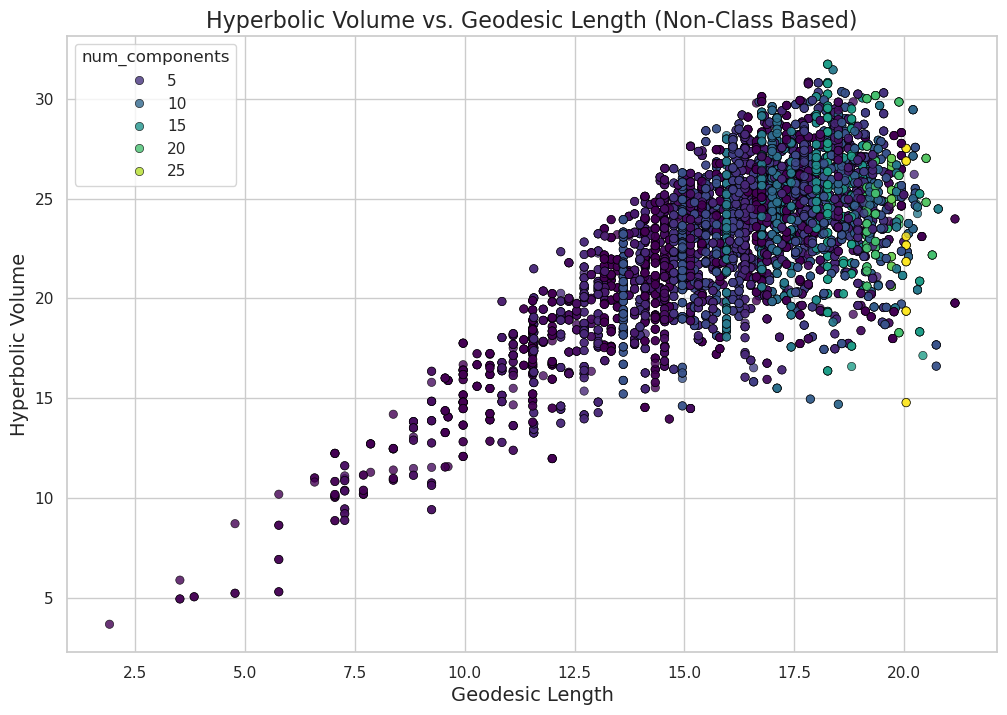

In [15]:
df = pd.read_csv(CSV_FILE)
print(f"Loaded {len(df)} rows.")
df_clean = df.dropna(subset=['hyperbolic_volume', 'geodesic_length', 'field_discriminant'])
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))
scatter = sns.scatterplot(
    data=df_clean,
    x='geodesic_length',
    y='hyperbolic_volume',
    hue='num_components',
    palette='viridis',
    sizes=(50, 200),
    alpha=0.8,
    edgecolor='black'
)
plt.title('Hyperbolic Volume vs. Geodesic Length (Non-Class Based)', fontsize=16)
plt.xlabel('Geodesic Length', fontsize=14)
plt.ylabel('Hyperbolic Volume', fontsize=14)
plt.show()

Loaded 766150 rows.


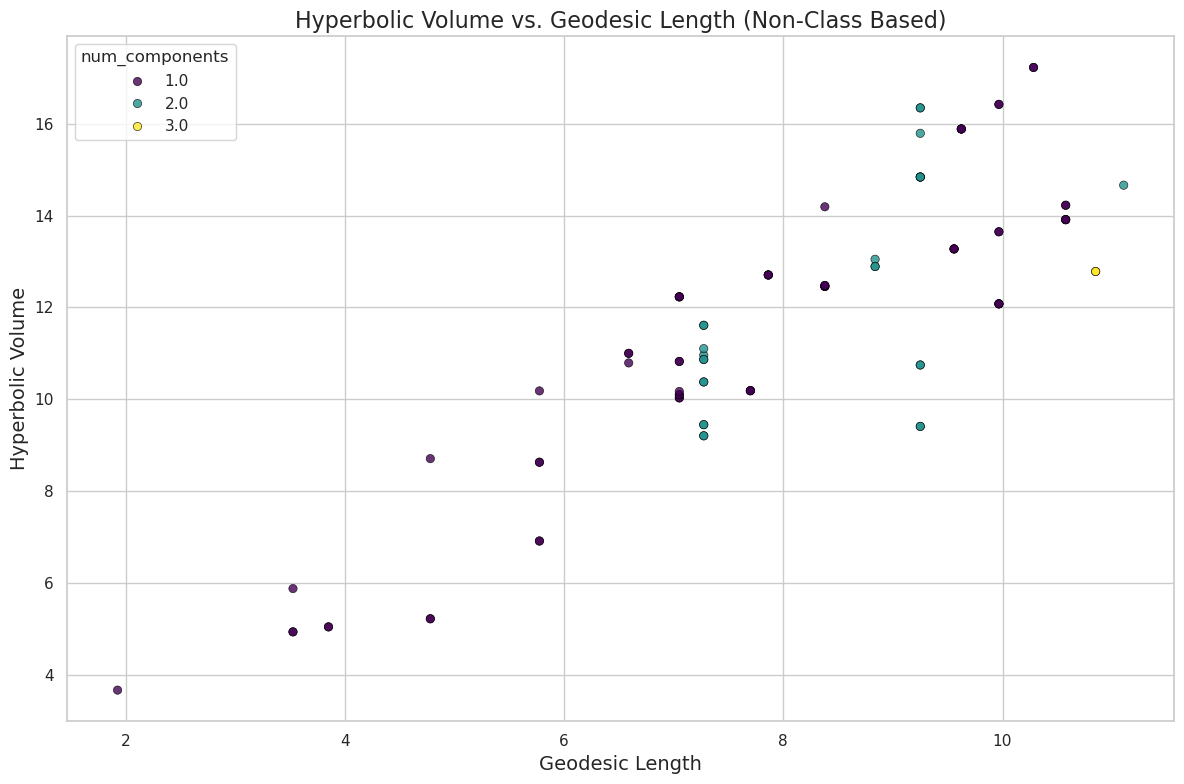

Loaded 766150 rows.


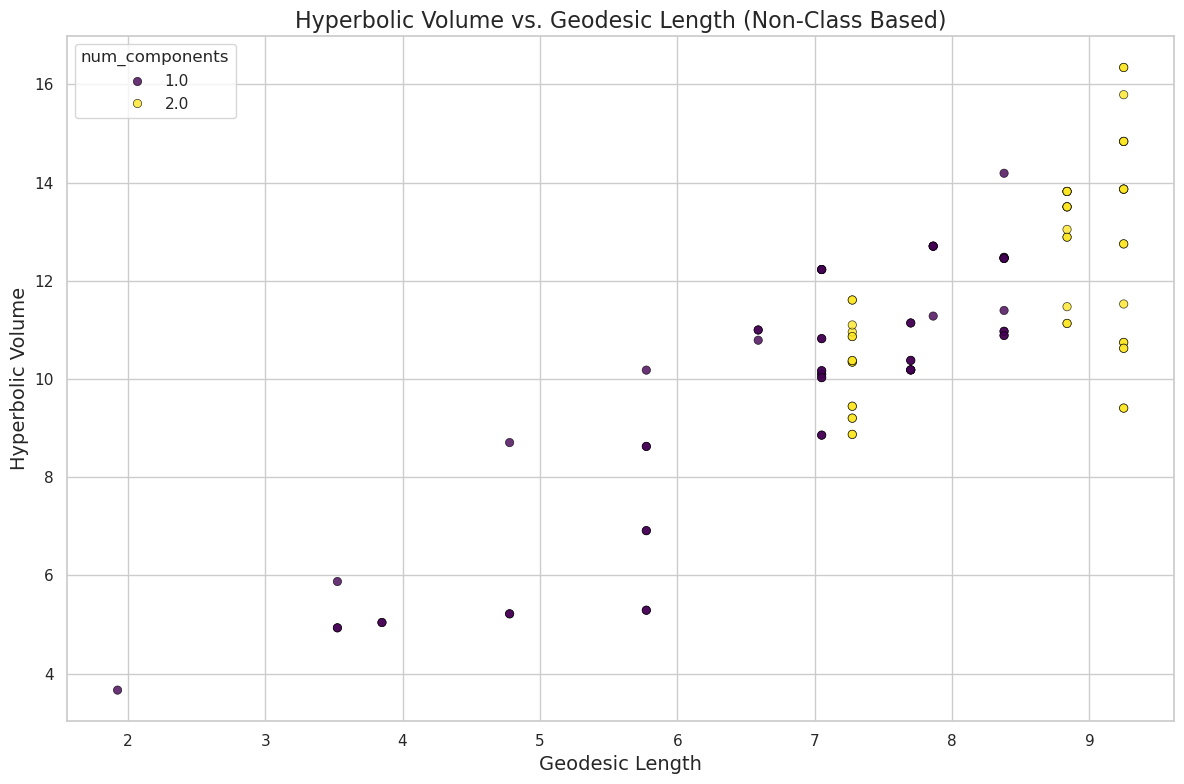

In [5]:
df = pd.read_csv(CSV_FILE)
print(f"Loaded {len(df)} rows.")
df=df.head(int(1000))
df_clean = df.dropna(subset=['hyperbolic_volume', 'geodesic_length', 'field_discriminant'])
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))
scatter = sns.scatterplot(
    data=df_clean,
    x='geodesic_length',
    y='hyperbolic_volume',
    hue='num_components',
    palette='viridis',
    sizes=(50, 200),
    alpha=0.8,
    edgecolor='black'
)
plt.title('Hyperbolic Volume vs. Geodesic Length (Non-Class Based)', fontsize=16)
plt.xlabel('Geodesic Length', fontsize=14)
plt.ylabel('Hyperbolic Volume', fontsize=14)
plt.tight_layout()
plt.show()
df = pd.read_csv(CSV_FILE)
print(f"Loaded {len(df)} rows.")
df=df.sort_values(by='geodesic_length').head(int(1000))
df_clean = df.dropna(subset=['hyperbolic_volume', 'geodesic_length', 'field_discriminant'])
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))
scatter = sns.scatterplot(
    data=df_clean,
    x='geodesic_length',
    y='hyperbolic_volume',
    hue='num_components',
    palette='viridis',
    sizes=(50, 200),
    alpha=0.8,
    edgecolor='black'
)
plt.title('Hyperbolic Volume vs. Geodesic Length (Non-Class Based)', fontsize=16)
plt.xlabel('Geodesic Length', fontsize=14)
plt.ylabel('Hyperbolic Volume', fontsize=14)
plt.tight_layout()
plt.show()

Filtered down to 7186 fundamental knots (removed powers).


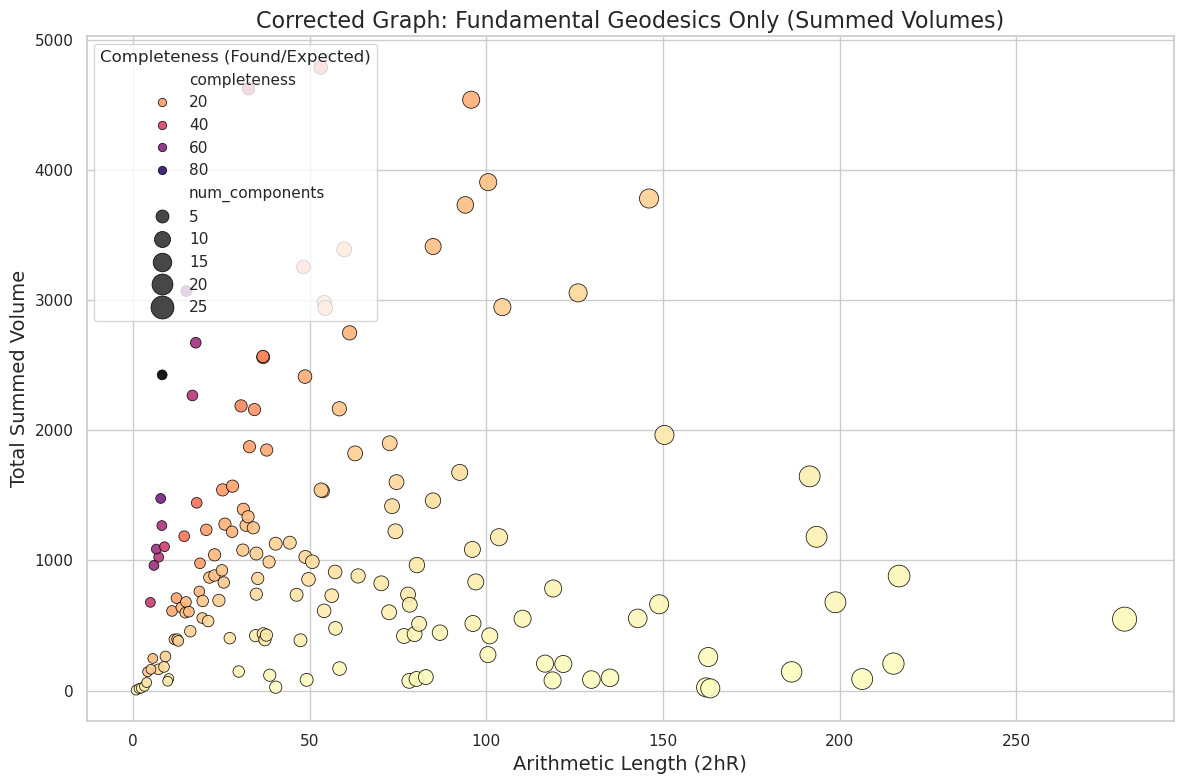

In [6]:
df = pd.read_csv(CSV_FILE)
df_clean = df.dropna(subset=['hyperbolic_volume', 'two_h_R', 'field_discriminant', 'geodesic_length'])
min_lengths = df_clean.groupby('field_discriminant')['geodesic_length'].transform('min')
df_fundamental = df_clean[np.abs(df_clean['geodesic_length'] - min_lengths) < 1e-6].copy()
print(f"Filtered down to {len(df_fundamental)} fundamental knots (removed powers).")
field_data = df_fundamental.groupby('field_discriminant').agg({
    'hyperbolic_volume': 'sum',          # Sum actual volumes found
    'two_h_R': 'first',                  # Constant for the field
    'num_components': 'first',           # Expected count
    'word': 'count'                      # Actual count found
}).reset_index()
field_data['completeness'] = field_data['word'] / field_data['num_components']
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))
scatter = sns.scatterplot(
    data=field_data,
    x='two_h_R',
    y='hyperbolic_volume',
    hue='completeness',
    palette='magma_r',
    size='num_components',
    sizes=(50, 300),
    edgecolor='black',
    alpha=0.9
)
x_max = field_data['two_h_R'].max()
x_range = np.linspace(0, x_max, 100)
plt.title('Corrected Graph: Fundamental Geodesics Only (Summed Volumes)', fontsize=16)
plt.xlabel('Arithmetic Length (2hR)', fontsize=14)
plt.ylabel('Total Summed Volume', fontsize=14)
plt.legend(title='Completeness (Found/Expected)', loc='upper left')
plt.tight_layout()
plt.show()

Loaded 766150 rows.
Plotting 7442 points with Arithmetic Length < 100.


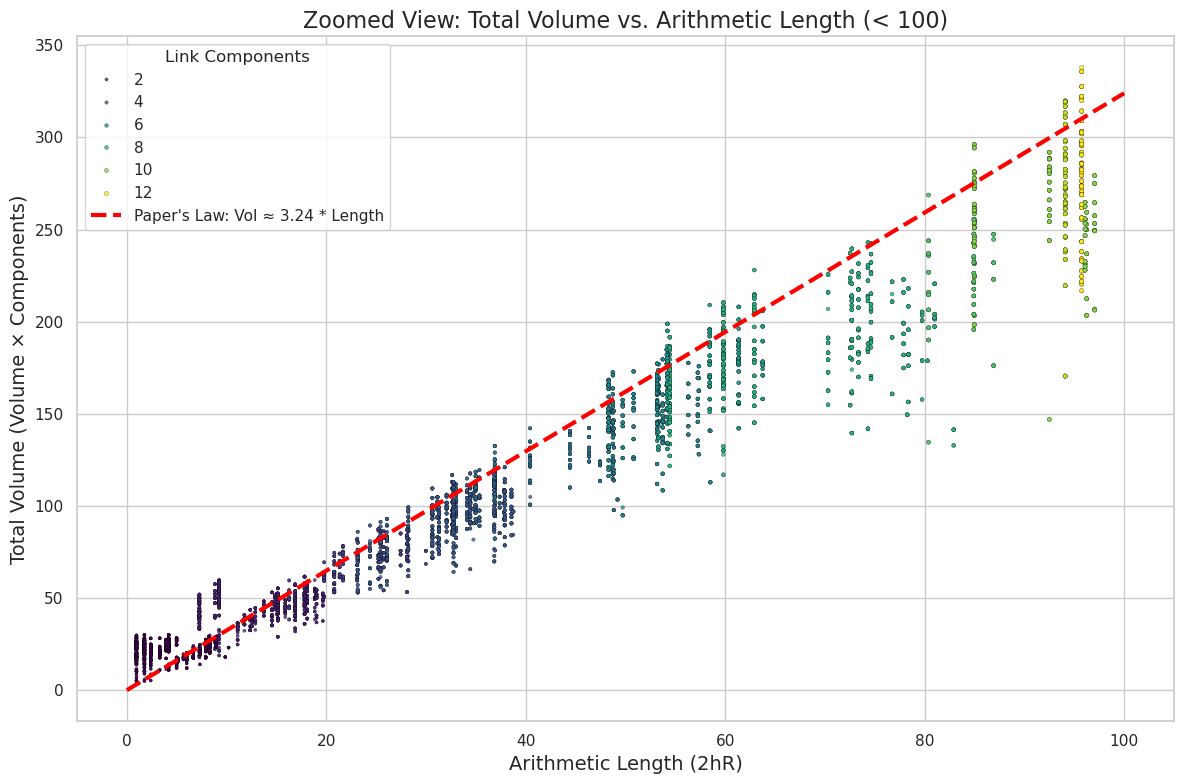

In [7]:
df = pd.read_csv(CSV_FILE)
print(f"Loaded {len(df)} rows.")
df_clean = df.dropna(subset=['total_volume', 'two_h_R', 'field_discriminant'])
df_filtered = df_clean[df_clean['two_h_R'] < 100].copy()
print(f"Plotting {len(df_filtered)} points with Arithmetic Length < 100.")
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))
scatter = sns.scatterplot(
    data=df_filtered,
    x='two_h_R',
    y='total_volume',
    hue='num_components',
    palette='viridis',
    size='num_components',
    sizes=(5, 10),
    alpha=0.8,
    edgecolor='black'
)
x_range = np.linspace(0, 100, 100)
y_line = 3.24 * x_range
plt.plot(x_range, y_line, color='red', linestyle='--', linewidth=3, label='Paper\'s Law: Vol ≈ 3.24 * Length')
plt.title('Zoomed View: Total Volume vs. Arithmetic Length (< 100)', fontsize=16)
plt.xlabel('Arithmetic Length (2hR)', fontsize=14)
plt.ylabel('Total Volume (Volume × Components)', fontsize=14)
plt.legend(title='Link Components', loc='upper left')
plt.tight_layout()
plt.show()

Loaded 766150 rows.
Aggregating 7442 points with Arithmetic Length < 100.


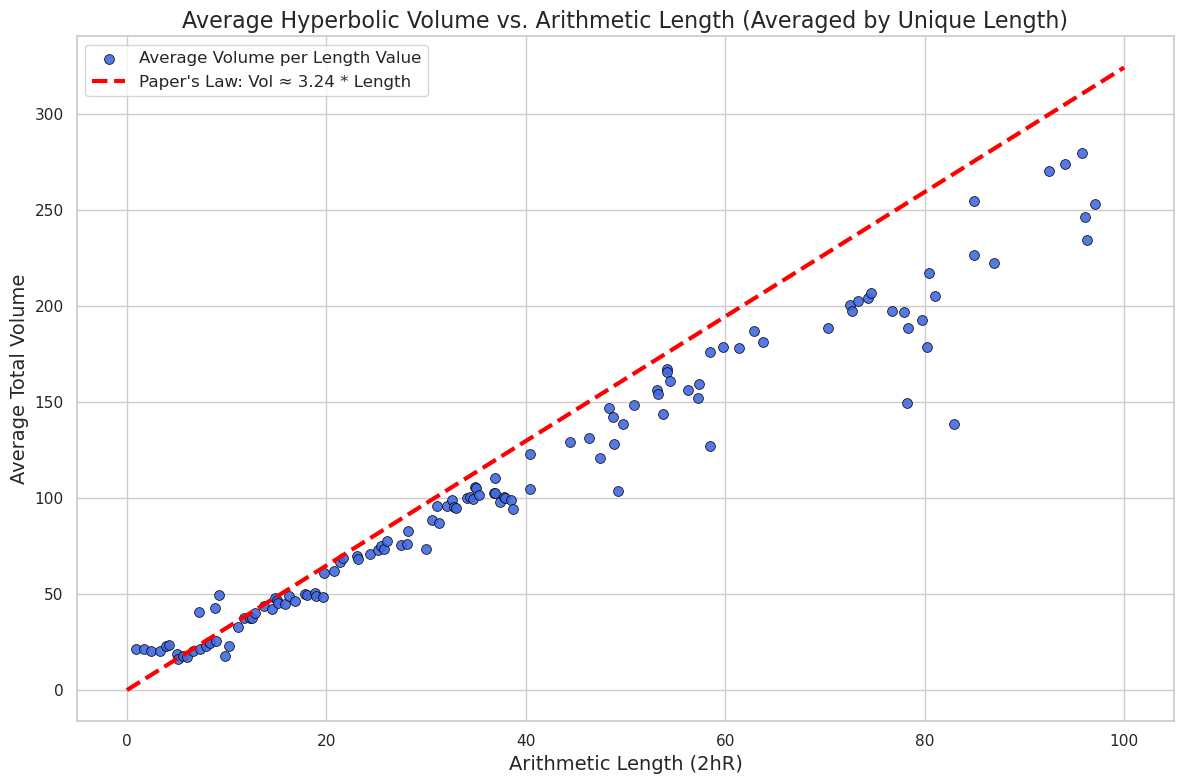

In [8]:
df = pd.read_csv(CSV_FILE)
print(f"Loaded {len(df)} rows.")
df_clean = df.dropna(subset=['total_volume', 'two_h_R', 'field_discriminant'])
df_filtered = df_clean[df_clean['two_h_R'] < 100].copy()
print(f"Aggregating {len(df_filtered)} points with Arithmetic Length < 100.")
df_averaged = df_filtered.groupby('two_h_R')['total_volume'].mean().reset_index()
df_averaged.rename(columns={'total_volume': 'average_volume'}, inplace=True)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))
scatter = sns.scatterplot(
    data=df_averaged,
    x='two_h_R',
    y='average_volume',
    color='royalblue',
    s=50, # Set size larger for visibility
    alpha=0.9,
    edgecolor='black',
    label='Average Volume per Length Value'
)
x_range = np.linspace(0, 100, 100)
y_line = 3.24 * x_range
plt.plot(x_range, y_line, color='red', linestyle='--', linewidth=3, label='Paper\'s Law: Vol ≈ 3.24 * Length')
plt.title('Average Hyperbolic Volume vs. Arithmetic Length (Averaged by Unique Length)', fontsize=16)
plt.xlabel('Arithmetic Length (2hR)', fontsize=14)
plt.ylabel('Average Total Volume', fontsize=14)
plt.legend(loc='upper left', fontsize=12)
plt.tight_layout()
plt.show()

Successfully loaded 766150 rows.
First 5 rows of the processed DataFrame (df_processed_data):
   field_discriminant  super_volume   two_h_R
0                 5.0     21.178233  0.962424
1                 8.0     21.191982  1.762747
2                13.0     20.210265  2.389526
3                17.0     23.668829  4.189425
4                29.0     20.424213  3.294462


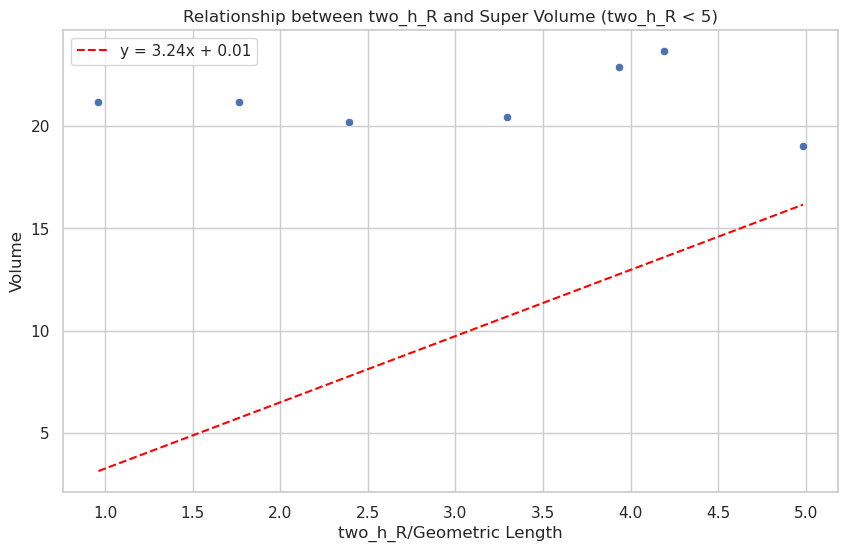

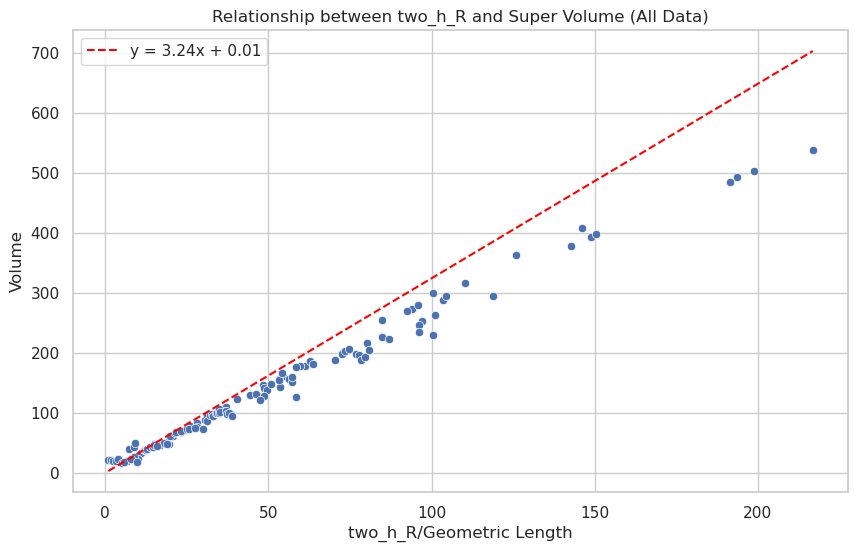


First 5 rows of the Averaged DataFrame (df_averaged):
    two_h_R  avg_super_volume
0  0.962424         21.178233
1  1.762747         21.191982
2  2.389526         20.210265
3  3.294462         20.424213
4  3.931441         22.888890


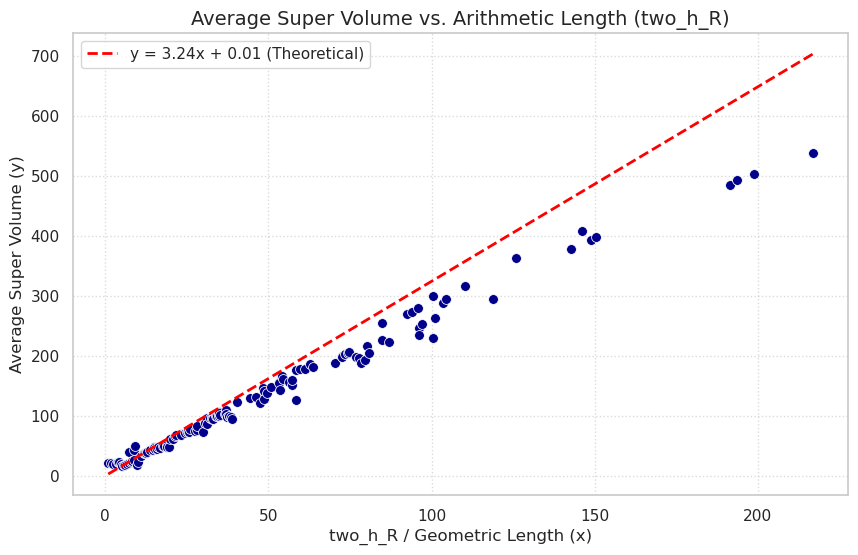

In [9]:
df = pd.read_csv(CSV_FILE)
print(f"Successfully loaded {len(df)} rows.")
df_filtered = df.dropna(subset=['field_discriminant']).copy()
df_filtered['num_components'] = pd.to_numeric(df_filtered['num_components'], errors='coerce')
df_filtered['hyperbolic_volume'] = pd.to_numeric(df_filtered['hyperbolic_volume'], errors='coerce')
df_filtered.dropna(subset=['num_components', 'hyperbolic_volume'], inplace=True)
df_filtered['num_components'] = df_filtered['num_components'].astype(int)
def calculate_super_volume_and_two_h_R(group):
    """
    Calculates super_volume (average of ALL available volumes * N) and extracts two_h_R
    for each group, where N = num_components.
    """
    num_components = group['num_components'].iloc[int(0)]
    if len(group) < num_components:
        return None
    all_volumes = group['hyperbolic_volume']
    overall_average = all_volumes.mean()
    super_volume = overall_average * num_components
    two_h_R = group['two_h_R'].iloc[int(0)]
    return pd.Series({
        'super_volume': super_volume,
        'two_h_R': two_h_R
    })
df_processed_data = df_filtered.groupby('field_discriminant').apply(
    calculate_super_volume_and_two_h_R,
    include_groups=False
)
df_processed_data.dropna(inplace=True)
df_processed_data = df_processed_data.reset_index()
print("First 5 rows of the processed DataFrame (df_processed_data):")
print(df_processed_data.head())
df_plot = df_processed_data[df_processed_data['two_h_R'] < 5].copy()


plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_plot, x='two_h_R', y='super_volume')
x_values = np.linspace(df_plot['two_h_R'].min(), df_plot['two_h_R'].max(), 10)
y_values = 3.24 * x_values + 0.01
plt.plot(x_values, y_values, color='red', linestyle='--', label='y = 3.24x + 0.01')
plt.title('Relationship between two_h_R and Super Volume (two_h_R < 5)')
plt.xlabel('two_h_R/Geometric Length')
plt.ylabel('Volume')
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_processed_data, x='two_h_R', y='super_volume')
x_values = np.linspace(df_processed_data['two_h_R'].min(), df_processed_data['two_h_R'].max(), 100)
y_values = 3.24 * x_values + 0.01
plt.plot(x_values, y_values, color='red', linestyle='--', label='y = 3.24x + 0.01')
plt.title('Relationship between two_h_R and Super Volume (All Data)')
plt.xlabel('two_h_R/Geometric Length')
plt.ylabel('Volume')
plt.grid(True)
plt.legend()
plt.show()

df_averaged = df_processed_data.groupby('two_h_R')['super_volume'].mean().reset_index()
df_averaged.rename(columns={'super_volume': 'avg_super_volume'}, inplace=True)
print("\nFirst 5 rows of the Averaged DataFrame (df_averaged):")
print(df_averaged.head())
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_averaged, x='two_h_R', y='avg_super_volume', s=50, color='darkblue')
x_values_avg = np.linspace(df_averaged['two_h_R'].min(), df_averaged['two_h_R'].max(), 100)
y_values_avg = 3.24 * x_values_avg + 0.01
plt.plot(x_values_avg, y_values_avg, color='red', linestyle='--', linewidth=2, label='y = 3.24x + 0.01 (Theoretical)')
plt.title('Average Super Volume vs. Arithmetic Length (two_h_R)', fontsize=14)
plt.xlabel('two_h_R / Geometric Length (x)', fontsize=12)
plt.ylabel('Average Super Volume (y)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

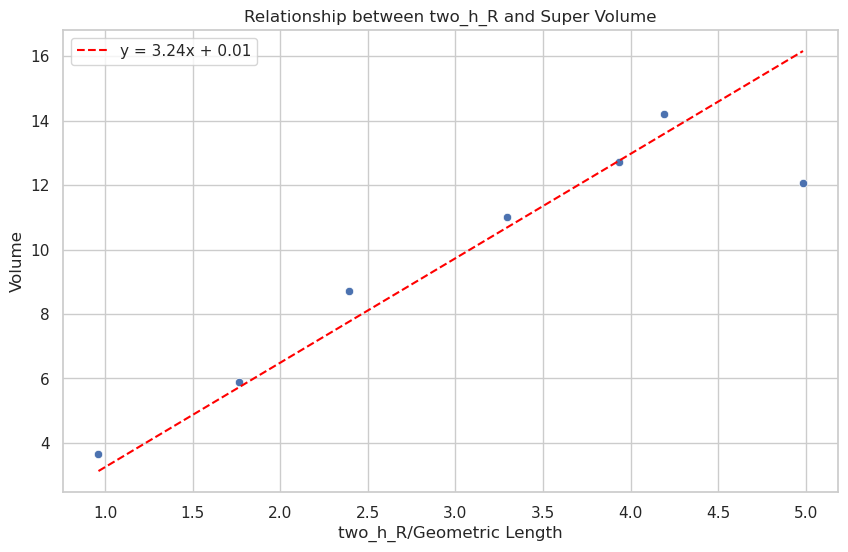

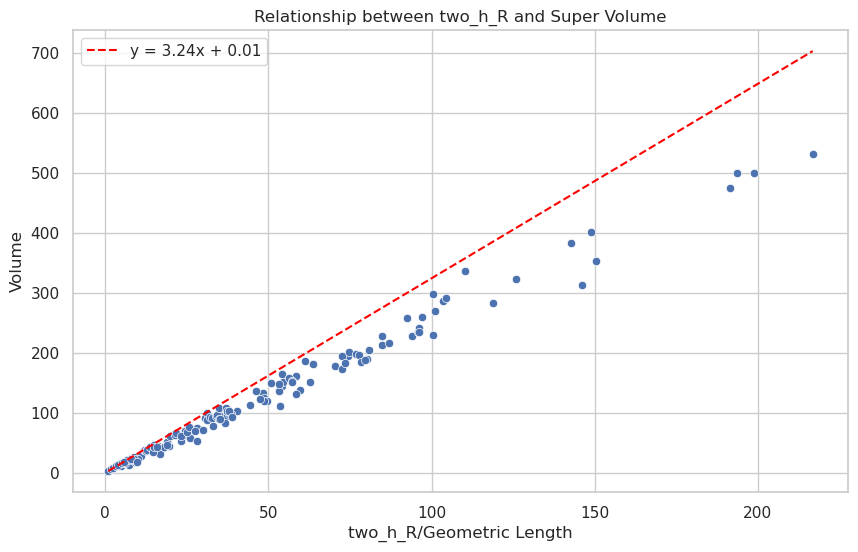

In [10]:
df = pd.read_csv(CSV_FILE)
df_filtered = df.dropna(subset=['field_discriminant']).copy()
df_filtered['num_components'] = pd.to_numeric(df_filtered['num_components'], errors='coerce')
df_filtered['hyperbolic_volume'] = pd.to_numeric(df_filtered['hyperbolic_volume'], errors='coerce')
df_filtered.dropna(subset=['num_components', 'hyperbolic_volume'], inplace=True)
df_filtered['num_components'] = df_filtered['num_components'].astype(int)
def calculate_super_volume_and_two_h_R(group):
    num_components = group['num_components'].iloc[int(0)]
    if len(group) < num_components:
        return None
    super_volume = group['hyperbolic_volume'].head(num_components).sum()
    two_h_R = group['two_h_R'].iloc[int(0)]
    return pd.Series({
        'super_volume': super_volume,
        'two_h_R': two_h_R
    })
df_processed_data = df_filtered.groupby('field_discriminant').apply(
    calculate_super_volume_and_two_h_R,
    include_groups=False
)
df_processed_data.dropna(inplace=True)
df_processed_data = df_processed_data.reset_index()
df_plot = df_processed_data[df_processed_data['two_h_R'] < 5].copy()
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_plot, x='two_h_R', y='super_volume')
x_values = np.linspace(df_plot['two_h_R'].min(), df_plot['two_h_R'].max(), int(10))
y_values = 3.24 * x_values + 0.01
plt.plot(x_values, y_values, color='red', linestyle='--', label='y = 3.24x + 0.01')
plt.title('Relationship between two_h_R and Super Volume')
plt.xlabel('two_h_R/Geometric Length')
plt.ylabel('Volume')
plt.grid(True)
plt.legend()
plt.show()


plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_processed_data, x='two_h_R', y='super_volume')
x_values = np.linspace(df_processed_data['two_h_R'].min(), df_processed_data['two_h_R'].max(), int(100))
y_values = 3.24 * x_values + 0.01
plt.plot(x_values, y_values, color='red', linestyle='--', label='y = 3.24x + 0.01')
plt.title('Relationship between two_h_R and Super Volume')
plt.xlabel('two_h_R/Geometric Length')
plt.ylabel('Volume')
plt.grid(True)
plt.legend()
plt.show()

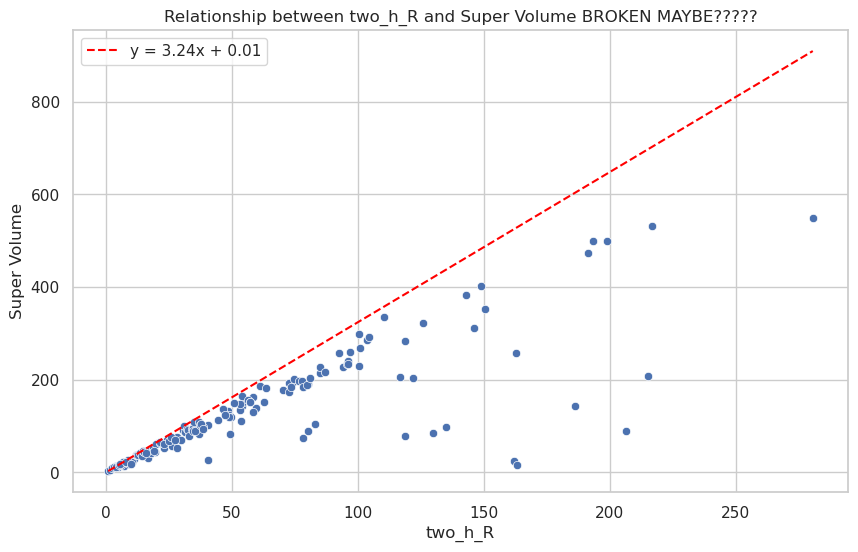

In [11]:
df2 = pd.read_csv(CSV_FILE)
df2_filtered = df2.dropna(subset=['field_discriminant']).copy()
df2_filtered['num_components'] = pd.to_numeric(df2_filtered['num_components'], errors='coerce')
df2_filtered['hyperbolic_volume'] = pd.to_numeric(df2_filtered['hyperbolic_volume'], errors='coerce')
df2_filtered.dropna(subset=['num_components', 'hyperbolic_volume'], inplace=True)
df2_filtered['num_components'] = df2_filtered['num_components'].astype(int)
def calculate_super_volume_and_two_h_R2(group):
    num_components2 = group['num_components'].iloc[int(0)]
    super_volume2 = group['hyperbolic_volume'].head(num_components2).sum()
    two_h_R2 = group['two_h_R'].iloc[int(0)]
    return pd.Series({
        'super_volume': super_volume2,
        'two_h_R': two_h_R2
    })
df2_processed_data = df2_filtered.groupby('field_discriminant').apply(
    calculate_super_volume_and_two_h_R2,
    include_groups=False # Omit this argument if you get a KeyError or AttributeError
)
df2_processed_data.dropna(inplace=True)
df2_processed_data = df2_processed_data.reset_index()
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df2_processed_data, x='two_h_R', y='super_volume')
x_values = np.linspace(df2_processed_data['two_h_R'].min(), df2_processed_data['two_h_R'].max(), int(100))
y_values = 3.24 * x_values + 0.01
plt.plot(x_values, y_values, color='red', linestyle='--', label='y = 3.24x + 0.01')
plt.title('Relationship between two_h_R and Super Volume BROKEN MAYBE?????')
plt.xlabel('two_h_R')
plt.ylabel('Super Volume')
plt.grid(True)
plt.legend()
plt.show()

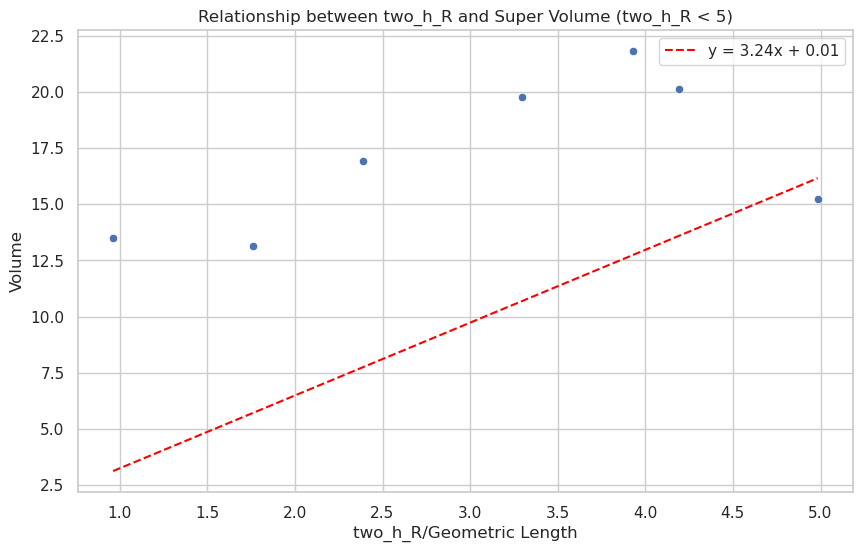

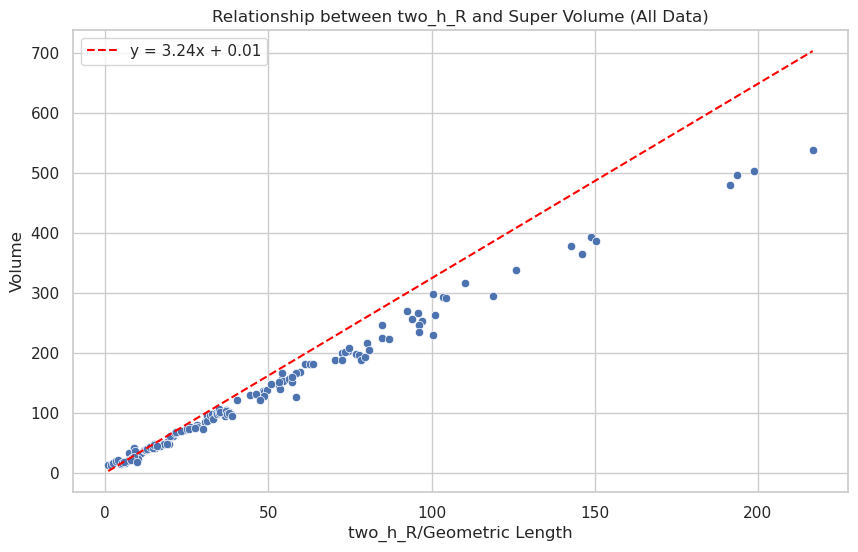

In [12]:
df = pd.read_csv(CSV_FILE)
df_filtered = df.dropna(subset=['field_discriminant']).copy()
df_filtered['num_components'] = pd.to_numeric(df_filtered['num_components'], errors='coerce')
df_filtered['hyperbolic_volume'] = pd.to_numeric(df_filtered['hyperbolic_volume'], errors='coerce')
df_filtered.dropna(subset=['num_components', 'hyperbolic_volume'], inplace=True)
df_filtered['num_components'] = df_filtered['num_components'].astype(int)
def calculate_super_volume_and_two_h_R(group):
    """
    Calculates super_volume (average of first N volumes * N) and extracts two_h_R
    for each group, where N = num_components.
    """
    num_components = group['num_components'].iloc[int(0)]
    if len(group) < num_components:
        return None
    head_volumes = group['hyperbolic_volume'].head(int(40))
    overall_average = head_volumes.mean()
    super_volume = overall_average * num_components
    two_h_R = group['two_h_R'].iloc[int(0)]
    return pd.Series({
        'super_volume': super_volume,
        'two_h_R': two_h_R
    })
df_processed_data = df_filtered.groupby('field_discriminant').apply(
    calculate_super_volume_and_two_h_R,
    include_groups=False
)
df_processed_data.dropna(inplace=True)
df_processed_data = df_processed_data.reset_index()
df_plot = df_processed_data[df_processed_data['two_h_R'] < 5].copy()
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_plot, x='two_h_R', y='super_volume')
x_values = np.linspace(df_plot['two_h_R'].min(), df_plot['two_h_R'].max(), 10)
y_values = 3.24 * x_values + 0.01
plt.plot(x_values, y_values, color='red', linestyle='--', label='y = 3.24x + 0.01')
plt.title('Relationship between two_h_R and Super Volume (two_h_R < 5)')
plt.xlabel('two_h_R/Geometric Length')
plt.ylabel('Volume')
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_processed_data, x='two_h_R', y='super_volume')
x_values = np.linspace(df_processed_data['two_h_R'].min(), df_processed_data['two_h_R'].max(), 100)
y_values = 3.24 * x_values + 0.01
plt.plot(x_values, y_values, color='red', linestyle='--', label='y = 3.24x + 0.01')
plt.title('Relationship between two_h_R and Super Volume (All Data)')
plt.xlabel('two_h_R/Geometric Length')
plt.ylabel('Volume')
plt.grid(True)
plt.legend()
plt.show()

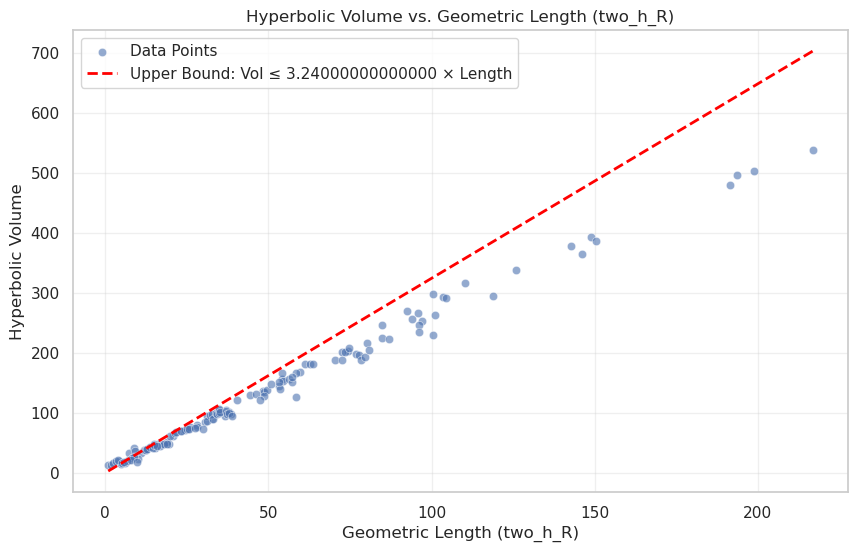

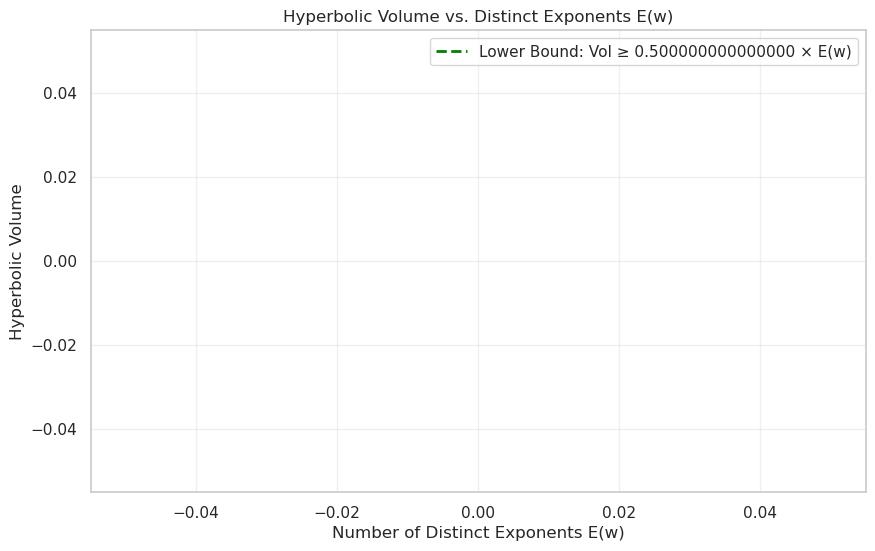

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import re

# --- 1. SETTING THE BOUNDS ---
# Adjust these slopes based on your theoretical constants or regression results
SLOPE_UPPER_BOUND = 3.24  # Bergeron's Bound (Vol <= C * Length)
SLOPE_LOWER_BOUND_COM = 0.5  # Hui et al. Bound (Vol >= C' * Exponents) - Placeholder value

# --- 2. PLOT 1: VOLUME VS LENGTH (Upper Bound) ---
# Assuming 'df_plot' or 'df_processed_data' is your dataframe from the previous cells
# We ensure we are using the dataset with 'two_h_R' and 'super_volume'

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_processed_data, x='two_h_R', y='super_volume', alpha=0.6, label='Data Points')

# Generate x-values for the lines
x_vals_len = np.linspace(df_processed_data['two_h_R'].min(), df_processed_data['two_h_R'].max(), 100)

# Add Upper Bound Line (Bergeron)
y_upper = SLOPE_UPPER_BOUND * x_vals_len
plt.plot(x_vals_len, y_upper, color='red', linestyle='--', linewidth=2, 
         label=f'Upper Bound: Vol ≤ {SLOPE_UPPER_BOUND} × Length')

# Formatting
plt.title('Hyperbolic Volume vs. Geometric Length (two_h_R)')
plt.xlabel('Geometric Length (two_h_R)')
plt.ylabel('Hyperbolic Volume')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# --- 3. PLOT 2: VOLUME VS DISTINCT EXPONENTS (Lower Bound) ---
# We need to compute E(w) from the 'word' column. 
# Assuming the 'word' column exists in your original 'df' or 'df_filtered'.

def count_distinct_exponents(word):
    """
    Parses a modular word (e.g., 'R2L3R1') and counts distinct exponents.
    """
    if not isinstance(word, str):
        return 0
    # Find all sequences of digits (the exponents)
    # Adjust regex if your word format is different (e.g., just 'LLRLL')
    # If format is 'R^2 L^3', regex for digits works.
    # If format is 'R, R, L, L, L', we need to count run lengths.
    
    # CASE A: Word format is 'R2L3...' (integers embedded)
    exponents = re.findall(r'\d+', word)
    if exponents:
        return len(set(exponents))
    
    # CASE B: Word format is 'RRLLLR' (no integers)
    # We count run lengths: RR -> 2, LLL -> 3, R -> 1. Exponents = {1, 2, 3} -> Count = 3
    if not exponents and ('R' in word or 'L' in word):
        # Simple run-length encoding
        import itertools
        run_lengths = [len(list(g)) for k, g in itertools.groupby(word)]
        return len(set(run_lengths))
        
    return 0

# Apply to dataframe (Ensure you have the 'word' column available)
# If 'word' was lost in grouping, you might need to merge it back or use 'df_filtered' before grouping
if 'word' in df_filtered.columns:
    df_filtered['E_w'] = df_filtered['word'].apply(count_distinct_exponents)
    
    # Group by E(w) to see the range or plot directly
    plt.figure(figsize=(10, 6))
    
    # Filter for valid data
    df_lower_plot = df_filtered[df_filtered['E_w'] > 0]
    
    sns.scatterplot(data=df_lower_plot, x='E_w', y='hyperbolic_volume', alpha=0.6)
    
    # Add Lower Bound Line (Hui et al.)
    x_vals_exp = np.linspace(df_lower_plot['E_w'].min(), df_lower_plot['E_w'].max(), 100)
    y_lower = SLOPE_LOWER_BOUND_COM * x_vals_exp
    plt.plot(x_vals_exp, y_lower, color='green', linestyle='--', linewidth=2,
             label=f'Lower Bound: Vol ≥ {SLOPE_LOWER_BOUND_COM} × E(w)')
             
    plt.title('Hyperbolic Volume vs. Distinct Exponents E(w)')
    plt.xlabel('Number of Distinct Exponents E(w)')
    plt.ylabel('Hyperbolic Volume')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()
else:
    print("Column 'word' not found. Cannot generate Lower Bound plot (Volume vs E(w)).")

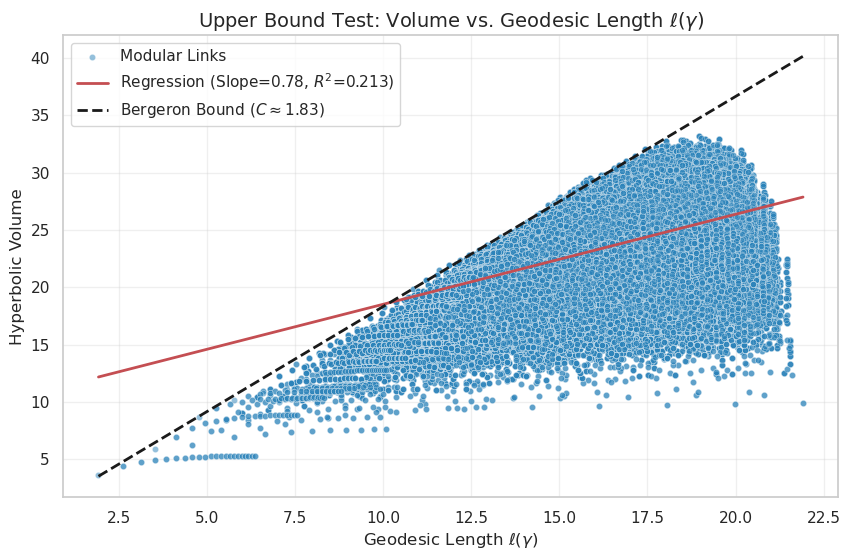

--- Upper Bound Stats ---
Regression Slope: 0.7848
Correlation (R^2): 0.2131


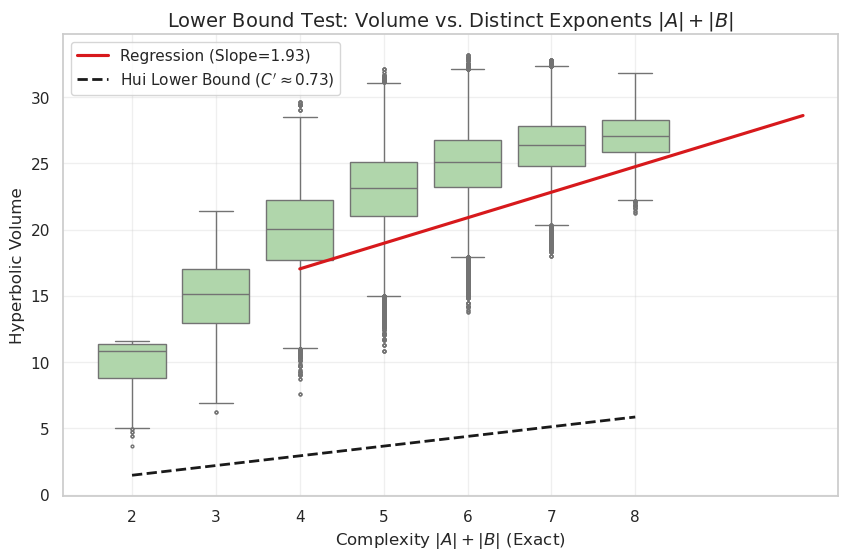

--- Lower Bound Stats ---
Regression Slope: 1.9286
Correlation (R^2): 0.2645


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np
import itertools
import pandas as pd

# ==========================================
# 1. SETUP & DATA CLEANING
# ==========================================

# Ensure we have a working copy of the dataframe
if 'df' in locals():
    plot_df = df.copy()
else:
    raise ValueError("DataFrame 'df' not found. Please run your data generation cells first.")

# HELPER: distinct_exponents_exact
# Calculates |A| + |B| where A is set of X-exponents and B is set of Y-exponents
def count_distinct_exponents_exact(word):
    if not isinstance(word, str) or not word:
        return 0
    
    # Group by character AND run length
    # e.g., "XXYXXX" -> [('X', 2), ('Y', 1), ('X', 3)]
    groups = [(k, len(list(g))) for k, g in itertools.groupby(word)]
    
    # Extract X (Left) exponents and Y (Right) exponents separately
    # Note: Using 'X' and 'Y' as they appear in your generation code
    x_exponents = set(count for char, count in groups if char == 'X')
    y_exponents = set(count for char, count in groups if char == 'Y')
    
    # The invariant is the sum of the cardinalities
    return len(x_exponents) + len(y_exponents)

# Apply the exact math
plot_df['E_w_exact'] = plot_df['word'].apply(count_distinct_exponents_exact)

# Ensure numeric types (Sage integers/reals can sometimes cause issues in Seaborn)
plot_df['hyperbolic_volume'] = plot_df['hyperbolic_volume'].astype(float)

# Calculate Geodesic Length from Trace if not already present
# Formula: Trace = 2 * cosh(Length / 2)  => Length = 2 * arccosh(Trace / 2)
if 'geodesic_length' not in plot_df.columns:
    if 'two_h_R' in plot_df.columns:
        # distinct from "2*h*R", usually Trace is stored. Assuming 'two_h_R' is the Trace.
        # Filter out traces < 2 (parabolic/elliptic) to avoid errors
        valid_trace = plot_df['two_h_R'].astype(float) > 2
        plot_df = plot_df[valid_trace].copy()
        plot_df['geodesic_length'] = 2 * np.arccosh(plot_df['two_h_R'].astype(float) / 2)
    else:
        print("Warning: Could not calculate Geodesic Length. Column 'two_h_R' missing.")

# Filter for valid regression data
reg_df = plot_df.dropna(subset=['hyperbolic_volume', 'geodesic_length', 'E_w_exact'])
reg_df = reg_df[reg_df['hyperbolic_volume'] > 0.001] # Filter failed computations

# ==========================================
# 2. UPPER BOUND ANALYSIS (Bergeron)
#    Vol <= C_M * Length
# ==========================================

# Linear Regression
slope_vol, intercept_vol, r_val_vol, p_val_vol, std_err_vol = stats.linregress(
    reg_df['geodesic_length'], 
    reg_df['hyperbolic_volume']
)

plt.figure(figsize=(10, 6))

# Plot Data
sns.scatterplot(
    data=reg_df, 
    x='geodesic_length', 
    y='hyperbolic_volume', 
    alpha=0.5, 
    s=20, 
    color='#2b83ba',
    label='Modular Links'
)

# Plot Regression Line
x_range_vol = np.linspace(reg_df['geodesic_length'].min(), reg_df['geodesic_length'].max(), 100)
y_reg_vol = intercept_vol + slope_vol * x_range_vol
plt.plot(x_range_vol, y_reg_vol, 'r-', linewidth=2, label=f'Regression (Slope={slope_vol:.2f}, $R^2$={r_val_vol**2:.3f})')

# Plot Bergeron Theoretical Upper Bound
# The constant C_M is related to the regular octahedron volume v8 approx 3.66
# Depending on normalization, C_M is often close to v8/2.
C_M_theory = 3.6638 / 2  
y_bound_vol = C_M_theory * x_range_vol
plt.plot(x_range_vol, y_bound_vol, 'k--', linewidth=2, label=f'Bergeron Bound ($C \\approx {C_M_theory:.2f}$)')

plt.title(r'Upper Bound Test: Volume vs. Geodesic Length $\ell(\gamma)$', fontsize=14)
plt.xlabel(r'Geodesic Length $\ell(\gamma)$', fontsize=12)
plt.ylabel('Hyperbolic Volume', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"--- Upper Bound Stats ---")
print(f"Regression Slope: {slope_vol:.4f}")
print(f"Correlation (R^2): {r_val_vol**2:.4f}")

# ==========================================
# 3. LOWER BOUND ANALYSIS (Hui et al.)
#    Vol >= C' * (|A| + |B|)
# ==========================================

# Linear Regression for Combinatorial Complexity
slope_comb, intercept_comb, r_val_comb, p_val_comb, std_err_comb = stats.linregress(
    reg_df['E_w_exact'], 
    reg_df['hyperbolic_volume']
)

plt.figure(figsize=(10, 6))

# Plot Data (Boxplot preferred for discrete X)
sns.boxplot(
    data=reg_df,
    x='E_w_exact',
    y='hyperbolic_volume',
    color='#abdda4',
    fliersize=2,
    linewidth=1
)

# Overlay Regression Line
# Note: boxplot is categorical 0,1,2... so we map x-values to 0..(N-1) for alignment, 
# or just use regplot which handles it automatically over the discrete buckets.
sns.regplot(
    data=reg_df, 
    x='E_w_exact', 
    y='hyperbolic_volume', 
    scatter=False, 
    color='#d7191c',
    label=f'Regression (Slope={slope_comb:.2f})'
)

# Plot Hui et al. Theoretical Lower Bound
# We need to plot this on the same axes. 
# Note: We must be careful aligning the line with the boxplot integers.
x_range_comb = np.linspace(reg_df['E_w_exact'].min(), reg_df['E_w_exact'].max(), 100)
# Theoretical Constant C' (Placeholder: Adjust based on Theorem constant, e.g., v3/something)
C_prime_theory = 3.6638 * 0.2 
y_bound_comb = C_prime_theory * x_range_comb

plt.plot(x_range_comb - reg_df['E_w_exact'].min(), y_bound_comb, 'k--', linewidth=2, label=f'Hui Lower Bound ($C\' \\approx {C_prime_theory:.2f}$)')
# Note on plotting: Seaborn boxplots re-index X to 0, 1, 2... 
# If alignment looks off, switch sns.boxplot to sns.scatterplot or adjust x-coords.

plt.title(r'Lower Bound Test: Volume vs. Distinct Exponents $|A|+|B|$', fontsize=14)
plt.xlabel(r'Complexity $|A| + |B|$ (Exact)', fontsize=12)
plt.ylabel('Hyperbolic Volume', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"--- Lower Bound Stats ---")
print(f"Regression Slope: {slope_comb:.4f}")
print(f"Correlation (R^2): {r_val_comb**2:.4f}")